In [1]:
import pandas as pd
pd.set_option('display.max_columns', 200)
import numpy as np
import math,os,re,pickle,joblib
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold,train_test_split
from model_tools.feature_select import by_missing_nunique_iv
from model_tools.plot import metric_report_plot
from model_tools.gentools import calculate_ks,calc_auc,calculate_psi
from model_tools.metric_report.metric_report import generate_metric_table
from model_tools.model import balance_sampling_by_category
from tqdm import tqdm

In [2]:
file_path = '/Users/mayongzhi/Job/Job_xyd/数据/百行多头/'

raw_high = pd.read_pickle('high_raw_df.pkl')
print(raw_high.shape)
print(raw_high.info())
raw_high.head(1)

(1659298, 422)
<class 'pandas.core.frame.DataFrame'>
Index: 1659298 entries, 65612 to 2235469
Columns: 422 entries, test_id to 手机号近24个月内查询机构数-其他机构
dtypes: float16(416), float64(1), int64(2), object(3)
memory usage: 1.4+ GB
None


,test_id,id_number,mobile,apply_date,flag,合作方,证件号近3天内查询笔数,证件号近3天内查询笔数-银行类机构,证件号近3天内查询笔数-非银类机构,证件号近3天内查询笔数-传统银行,证件号近3天内查询笔数-网络零售银行,证件号近3天内查询笔数-助贷类机构,证件号近3天内查询笔数-融资租赁类机构,证件号近3天内查询笔数-汽车金融类机构,证件号近3天内查询笔数-消费金融类机构,证件号近3天内查询笔数-小贷类机构,证件号近3天内查询笔数-网络小贷类机构,证件号近3天内查询笔数-信托类机构,证件号近3天内查询笔数-其他机构,证件号近7天内查询笔数,证件号近7天内查询笔数-银行类机构,证件号近7天内查询笔数-非银类机构,证件号近7天内查询笔数-传统银行,证件号近7天内查询笔数-网络零售银行,证件号近7天内查询笔数-助贷类机构,证件号近7天内查询笔数-融资租赁类机构,证件号近7天内查询笔数-汽车金融类机构,证件号近7天内查询笔数-消费金融类机构,证件号近7天内查询笔数-小贷类机构,证件号近7天内查询笔数-网络小贷类机构,证件号近7天内查询笔数-信托类机构,证件号近7天内查询笔数-其他机构,证件号近1个月内查询笔数,证件号近1个月内查询笔数-银行类机构,证件号近1个月内查询笔数-非银类机构,证件号近1个月内查询笔数-传统银行,证件号近1个月内查询笔数-网络零售银行,证件号近1个月内查询笔数-助贷类机构,证件号近1个月内查询笔数-融资租赁类机构,证件号近1个月内查询笔数-汽车金融类机构,证件号近1个月内查询笔数-消费金融类机构,证件号近1个月内查询笔数-小贷类机构,证件号近1个月内查询笔数-网络小贷类机构,证件号近1个月内查询笔数-信托类机构,证件号近1个月内查询笔数-其他机构,证件号近2个月内查询笔数,证件号近2个月内查询笔数-银行类机构,证件号近2个月内查询笔数-非银类机构,证件号近2个月内查询笔数-传统银行,证件号近2个月内查询笔数-网络零售银行,证件号近2个月内查询笔数-助贷类机构,证件号近2个月内查询笔数-融资租赁类机构,证件号近2个月内查询笔数-汽车金融类机构,证件号近2个月内查询笔数-消费金融类机构,证件号近2个月内查询笔数-小贷类机构,证件号近2个月内查询笔数-网络小贷类机构,证件号近2个月内查询笔数-信托类机构,证件号近2个月内查询笔数-其他机构,证件号近3个月内查询笔数,证件号近3个月内查询笔数-银行类机构,证件号近3个月内查询笔数-非银类机构,证件号近3个月内查询笔数-传统银行,证件号近3个月内查询笔数-网络零售银行,证件号近3个月内查询笔数-助贷类机构,证件号近3个月内查询笔数-融资租赁类机构,证件号近3个月内查询笔数-汽车金融类机构,证件号近3个月内查询笔数-消费金融类机构,证件号近3个月内查询笔数-小贷类机构,证件号近3个月内查询笔数-网络小贷类机构,证件号近3个月内查询笔数-信托类机构,证件号近3个月内查询笔数-其他机构,证件号近6个月内查询笔数,证件号近6个月内查询笔数-银行类机构,证件号近6个月内查询笔数-非银类机构,证件号近6个月内查询笔数-传统银行,证件号近6个月内查询笔数-网络零售银行,证件号近6个月内查询笔数-助贷类机构,证件号近6个月内查询笔数-融资租赁类机构,证件号近6个月内查询笔数-汽车金融类机构,证件号近6个月内查询笔数-消费金融类机构,证件号近6个月内查询笔数-小贷类机构,证件号近6个月内查询笔数-网络小贷类机构,证件号近6个月内查询笔数-信托类机构,证件号近6个月内查询笔数-其他机构,证件号近12个月内查询笔数,证件号近12个月内查询笔数-银行类机构,证件号近12个月内查询笔数-非银类机构,证件号近12个月内查询笔数-传统银行,证件号近12个月内查询笔数-网络零售银行,证件号近12个月内查询笔数-助贷类机构,证件号近12个月内查询笔数-融资租赁类机构,证件号近12个月内查询笔数-汽车金融类机构,证件号近12个月内查询笔数-消费金融类机构,证件号近12个月内查询笔数-小贷类机构,证件号近12个月内查询笔数-网络小贷类机构,证件号近12个月内查询笔数-信托类机构,证件号近12个月内查询笔数-其他机构,证件号近24个月内查询笔数,证件号近24个月内查询笔数-银行类机构,证件号近24个月内查询笔数-非银类机构,...,手机号近3天内查询机构数-网络零售银行,手机号近3天内查询机构数-助贷类机构,手机号近3天内查询机构数-融资租赁类机构,手机号近3天内查询机构数-汽车金融类机构,手机号近3天内查询机构数-消费金融类机构,手机号近3天内查询机构数-小贷类机构,手机号近3天内查询机构数-网络小贷类机构,手机号近3天内查询机构数-信托类机构,手机号近3天内查询机构数-其他机构,手机号近7天内查询机构数,手机号近7天内查询机构数-银行类机构,手机号近7天内查询机构数-非银类机构,手机号近7天内查询机构数-传统银行,手机号近7天内查询机构数-网络零售银行,手机号近7天内查询机构数-助贷类机构,手机号近7天内查询机构数-融资租赁类机构,手机号近7天内查询机构数-汽车金融类机构,手机号近7天内查询机构数-消费金融类机构,手机号近7天内查询机构数-小贷类机构,手机号近7天内查询机构数-网络小贷类机构,手机号近7天内查询机构数-信托类机构,手机号近7天内查询机构数-其他机构,手机号近1个月内查询机构数,手机号近1个月内查询机构数-银行类机构,手机号近1个月内查询机构数-非银类机构,手机号近1个月内查询机构数-传统银行,手机号近1个月内查询机构数-网络零售银行,手机号近1个月内查询机构数-助贷类机构,手机号近1个月内查询机构数-融资租赁类机构,手机号近1个月内查询机构数-汽车金融类机构,手机号近1个月内查询机构数-消费金融类机构,手机号近1个月内查询机构数-小贷类机构,手机号近1个月内查询机构数-网络小贷类机构,手机号近1个月内查询机构数-信托类机构,手机号近1个月内查询机构数-其他机构,手机号近2个月内查询机构数,手机号近2个月内查询机构数-银行类机构,手机号近2个月内查询机构数-非银类机构,手机号近2个月内查询机构数-传统银行,手机号近2个月内查询机构数-网络零售银行,手机号近2个月内查询机构数-助贷类机构,手机号近2个月内查询机构数-融资租赁类机构,手机号近2个月内查询机构数-汽车金融类机构,手机号近2个月内查询机构数-消费金融类机构,手机号近2个月内查询机构数-小贷类机构,手机号近2个月内查询机构数-网络小贷类机构,手机号近2个月内查询机构数-信托类机构,手机号近2个月内查询机构数-其他机构,手机号近3个月内查询机构数,手机号近3个月内查询机构数-银行类机构,手机号近3个月内查询机构数-非银类机构,手机号近3个月内查询机构数-传统银行,手机号近3个月内查询机构数-网络零售银行,手机号近3个月内查询机构数-助贷类机构,手机号近3个月内查询机构数-融资租赁类机构,手机号近3个月内查询机构数-汽车金融类机构,手机号近3个月内查询机构数-消费金融类机构,手机号近3个月内查询机构数-小贷类机构,手机号近3个月内查询机构数-网络小贷类机构,手机号近3个月内查询机构数-信托类机构,手机号近3个月内查询机构数-其他机构,手机号近6个月内查询机构数,手机号近6个月内查询机构数-银行类机构,手机号近6个月内查询机构数-非银类机构,手机号近6个月内查询机构数-传统银行,手机号近6个月内查询机构数-网络零售银行,手机号近6个月内查询机构数-助贷类机构,手机号近6个月内查询机构数-融资租赁类机构,手机号近6个月内查询机构数-汽车金融类机构,手机号近6个月内查询机构数-消费金融类机构,手机号近6个月内查询机构数-小贷类机构,手机号近6个月内查询机构数-网络小贷类机构,手机号近6个月内查询机构数-信托类机构,手机号近6个月内查询机构数-其他机构,手机号近12个月内查询机构数,手机号近12个月内查询机构数-银行类机构,手机号近12个月内查询机构数-非银类机构,手机号近12个月内查询机构数-传统银行,手机号近12个月内查询机构数-网络零售银行,手机号近12个月内查询机构数-助贷类机构,手机号近12个月内查询机构数-融资租赁类机构,手机号近12个月内查询机构数-汽车金融类机构,手机号近12个月内查询机构数-消费金融类机构,手机号近12个月内查询机构数-小贷类机构,手机号近12个月内查询机构数-网络小贷类机构,手机号近12个月内查询机构数-信托类机构,手机号近12个月内查询机构数-其他机构,手机号近24个月内查询机构数,手机号近24个月内查询机构数-银行类机构,手机号近24个月内查询机构数-非银类机构,手机号近24个月内查询机构数-传统银行,手机号近24个月内查询机构数-网络零售银行,手机号近24个月内查询机构数-助贷类机构,手机号近24个月内查询机构数-融资租赁类机构,手机号近24个月内查询机构数-汽车金融类机构,手机号近24个月内查询机构数-消费金融类机构,手机号近24个月内查询机构数-小贷类机构,手机号近24个月内查询机构数-网络小贷类机构,手机号近24个月内查询机构数-信托类机构,手机号近24个月内查询机构数-其他机构
65612,138637,bc19a56414b6824e658d44337c56453d,0a0773f90564f7775e81a9074cbf1349,20230131,0.0,shanxiqn,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2

In [21]:
for file in ['百行衍生_同一时间窗口笔数除机构_high.pkl', '百行衍生_证件号和手机号的差异和比率_high.pkl', '百行衍生_证件号或手机号的滑动窗口变化率_high.pkl', '百行衍生_证件手机一致性_high.pkl', '不同机构占总机构比率_high.pkl']:
    feature_df = pd.read_pickle(os.path.join(file_path, file))
    print(feature_df.info())
    common_cols = feature_df.columns.tolist()[6:]
    # 以test_id为键，raw_high拼接feature_df
    raw_high = raw_high.merge(feature_df, on='test_id', how='inner', suffixes=('', '_drop'))
    raw_high = raw_high.loc[:, ~raw_high.columns.duplicated()]
    raw_high = raw_high.drop(columns=[col for col in raw_high.columns if '_drop' in col])
    print(raw_high.shape)
    print(raw_high.info())
    print('=' * 20)

<class 'pandas.core.frame.DataFrame'>
Index: 1659298 entries, 65612 to 2235469
Columns: 214 entries, test_id to 手机号近24个月内查询笔数/机构数-其他机构
dtypes: float16(208), float64(1), int64(2), object(3)
memory usage: 746.9+ MB
None
(1659298, 630)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1659298 entries, 0 to 1659297
Columns: 630 entries, test_id to 手机号近24个月内查询笔数/机构数-其他机构
dtypes: float16(624), float64(1), int64(2), object(3)
memory usage: 2.0+ GB
None
<class 'pandas.core.frame.DataFrame'>
Index: 1659298 entries, 65612 to 2235469
Columns: 422 entries, test_id to 证件号与手机号近24个月内查询机构数比率-其他机构
dtypes: float16(416), float64(1), int64(2), object(3)
memory usage: 1.4+ GB
None
(1659298, 1046)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1659298 entries, 0 to 1659297
Columns: 1046 entries, test_id to 证件号与手机号近24个月内查询机构数比率-其他机构
dtypes: float16(1040), float64(1), int64(2), object(3)
memory usage: 3.3+ GB
None
<class 'pandas.core.frame.DataFrame'>
Index: 1659298 entries, 65612 to 2235469
Columns: 370 e

In [155]:
raw_high.shape

(1659298, 2003)

In [156]:
raw_high.to_pickle('特征衍生_high_all.pkl')

In [3]:
raw_high = pd.read_pickle('特征衍生_high_all.pkl')

In [4]:
raw_high.shape

(1659298, 2003)

In [8]:
not_features = ['test_id',	'id_number', 'mobile', 'apply_date', 'flag', '合作方','month']
label = 'flag'
features = [col for col in raw_high.columns if col not in not_features]
len(features)

1996

In [130]:
raw_high.shape

(1659298, 2002)

## 去掉2023年12月之前的数据

In [132]:
raw_high['month'] = raw_high['apply_date'].apply(lambda x : int(str(x)[:6]))
raw_high['month'].value_counts()

/var/folders/v1/ch71pmtn60dbr0m_t7s_ch1m0000gn/T/ipykernel_2921/527855132.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  raw_high['month'] = raw_high['apply_date'].apply(lambda x : int(str(x)[:6]))


month
202401    239906
202403    181564
202404    172360
202406    143000
202402    140785
202405    125837
202407    119032
202312    110956
202409     76324
202311     75845
202410     63210
202408     62059
202207     29407
202206     27101
202208     22835
202301     20588
202305     17906
202302     12047
202303      9238
202304      9103
202209        81
202210        63
202211        30
202212        21
Name: count, dtype: int64

In [10]:
with pd.option_context('display.max_rows', None):
    result = raw_high[raw_high['month'] >= 202312].groupby('合作方')['month'].value_counts()
    display(result)

合作方            month 
hc_A           202409    17389
               202410    11498
               202408    11347
               202407     7696
               202406     6836
hc_B           202409     8765
               202410     4805
               202408     4707
               202406     4212
               202407     2421
hc_C           202409    21893
               202410    20457
               202408    13588
               202406    11732
               202407     7971
hc_new         202312    30000
               202401    30000
hc_old         202401    42215
               202312    36090
lexin_type1    202312    20198
               202401    15380
               202403    15061
               202404    14433
               202405    13562
               202406    12184
               202407    11615
               202402    11405
lexin_type2    202401    24798
               202403    24231
               202402    22491
               202407    14522
               20

In [11]:
raw_high[raw_high['month'] >= 202312].shape

(1435033, 2003)

In [12]:
raw_high_after_202312 = raw_high[raw_high['month'] >= 202312]
# raw_high_after_202312.to_pickle('raw_high_after_202312.pkl')

In [ ]:
del raw_high

NameError: name 'gc' is not defined

In [14]:
import gc
gc.collect()


0

# 均衡采样

In [137]:
from sklearn.utils import compute_class_weight


classes = np.unique(raw_high_after_202312[label])
class_weights = compute_class_weight(class_weight='balanced', classes=classes, y=raw_high_after_202312[label])
label_weight = dict(zip(classes, class_weights))
print(label_weight)

{0.0: 0.5640502673183033, 1.0: 4.403184334229292}


In [ ]:
# 调用函数进行采样
raw_high_after_202312 = balance_sampling_by_category(raw_high_after_202312, '合作方', label)
raw_high_after_202312.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 751891 entries, 0 to 751890
Columns: 2003 entries, test_id to month
dtypes: float16(1996), float64(1), int64(3), object(3)
memory usage: 2.8+ GB


In [141]:
sampled_data.shape

(751891, 2003)

In [142]:
sampled_data['合作方'].value_counts()

合作方
weixin_old       110620
lexin_type1       75593
lexin_type4       63080
lexin_type3       56765
zhongan_oldcg     55400
hc_new            52838
hc_old            47580
weixin_new        39002
hc_C              37664
weixin_oldjc      37324
lexin_type2       34934
yqg               31068
zhongan_newcg     29298
hc_A              23944
lexin_type5       19831
hc_B              12778
weixin_newjc      10840
zhongan_newzr      9123
zhongan_oldzr      4209
Name: count, dtype: int64

In [143]:
from sklearn.utils import compute_class_weight


classes = np.unique(sampled_data[label])
class_weights = compute_class_weight(class_weight='balanced', classes=classes, y=sampled_data[label])
label_weight = dict(zip(classes, class_weights))
print(label_weight)

{0.0: 0.5640499556646477, 1.0: 4.403203326305927}


In [144]:
oot_data = sampled_data[sampled_data['合作方'].isin(['shanxiqn','hc_old'])]
train_val_data = sampled_data[~sampled_data['合作方'].isin(['shanxiqn','hc_old'])]
print(train_val_data.shape ,oot_data.shape)
train_val_data = train_val_data[train_val_data[features].isnull().sum(axis=1)<len(features)].reset_index(drop=True)
oot_data = oot_data[oot_data[features].isnull().sum(axis=1)<len(features)].reset_index(drop=True)
print(train_val_data.shape ,oot_data.shape)

# train_val_data.to_pickle('train_val_data.pkl')
# oot_data.to_pickle('oot_data.pkl')

(704311, 2003) (47580, 2003)
(702785, 2003) (47580, 2003)


In [145]:
pd.DataFrame(train_val_data[train_val_data.duplicated(subset=features, keep=False)][features].fillna('none').value_counts())

count
证件号近3天内查询笔数 证件号近3天内查询笔数-银行类机构 证件号近3天内查询笔数-非银类机构 证件号近3天内查询笔数-传统银行 证件号近3天内查询笔数-网络零售银行 证件号近3天内查询笔数-助贷类机构 证件号近3天内查询笔数-融资租赁类机构 证件号近3天内查询笔数-汽车金融类机构 证件号近3天内查询笔数-消费金融类机构 证件号近3天内查询笔数-小贷类机构 证件号近3天内查询笔数-网络小贷类机构 证件号近3天内查询笔数-信托类机构 证件号近3天内查询笔数-其他机构 证件号近7天内查询笔数 证件号近7天内查询笔数-银行类机构 证件号近7天内查询笔数-非银类机构 证件号近7天内查询笔数-传统银行 证件号近7天内查询笔数-网络零售银行 证件号近7天内查询笔数-助贷类机构 证件号近7天内查询笔数-融资租赁类机构 证件号近7天内查询笔数-汽车金融类机构 证件号近7天内查询笔数-消费金融类机构 证件号近7天内查询笔数-小贷类机构 证件号近7天内查询笔数-网络小贷类机构 证件号近7天内查询笔数-信托类机构 证件号近7天内查询笔数-其他机构 证件号近1个月内查询笔数 证件号近1个月内查询笔数-银行类机构 证件号近1个月内查询笔数-非银类机构 证件号近1个月内查询笔数-传统银行 证件号近1个月内查询笔数-网络零售银行 证件号近1个月内查询笔数-助贷类机构 证件号近1个月内查询笔数-融资租赁类机构 证件号近1个月内查询笔数-汽车金融类机构 证件号近1个月内查询笔数-消费金融类机构 证件号近1个月内查询笔数-小贷类机构 证件号近1个月内查询笔数-网络小贷类机构 证件号近1个月内查询笔数-信托类机构 证件号近1个月内查询笔数-其他机构 证件号近2个月内查询笔数 证件号近2个月内查询笔数-银行类机构 证件号近2个月内查询笔数-非银类机构 证件号近2个月内查询笔数-传统银行 证件号近2个月内查询笔数-网络零售银行 证件号近2个月内查询笔数-助贷类机构 证件号近2个月内查询笔数-融资租赁类机构 证件号近2个月内查询笔数-汽车金融类机构 证件号近2个月内查询笔数-消费金融类机构 证件号近2个月内查询笔数-小贷类机构 证件号近2个月内查询笔数-网络小贷类机构 证件号近2个月内查询笔数-信托类机构 证件号近2个月内查询笔数-其他机构 证件号近3个月内查询笔数 证件号近3个月内查询笔数-银行类机构 证件号近3个月内查询笔数-非银类机构 证件号近3个月内查询笔数-传统银行 证件号近3个月内查询笔数-网络零售银行 证件号近3个月内查询笔数-助贷类机构 证件号近3个月内查询笔数-融资租赁类机构 证件号近3个月内查询笔数-汽车金融类机构 证件号近3个月内查询笔数-消费金融类机构 证件号近3个月内查询笔数-小贷类机构 证件号近3个月内查询笔数-网络小贷类机构 证件号近3个月内查询笔数-信托类机构 证件号近3个月内查询笔数-其他机构 证件号近6个月内查询笔数 证件号近6个月内查询笔数-银行类机构 证件号近6个月内查询笔数-非银类机构 证件号近6个月内查询笔数-传统银行 证件号近6个月内查询笔数-网络零售银行 证件号近6个月内查询笔数-助贷类机构 证件号近6个月内查询笔数-融资租赁类机构 证件号近6个月内查询笔数-汽车金融类机构 证件号近6个月内查询笔数-消费金融类机构 证件号近6个月内查询笔数-小贷类机构 证件号近6个月内查询笔数-网络小贷类机构 证件号近6个月内查询笔数-信托类机构 证件号近6个月内查询笔数-其他机构 证件号近12个月内查询笔数 证件号近12个月内查询笔数-银行类机构 证件号近12个月内查询笔数-非银类机构 证件号近12个月内查询笔数-传统银行 证件号近12个月内查询笔数-网络零售银行 证件号近12个月内查询笔数-助贷类机构 证件号近12个月内查询笔数-融资租赁类机构 证件号近12个月内查询笔数-汽车金融类机构 证件号近12个月内查询笔数-消费金融类机构 证件号近12个月内查询笔数-小贷类机构 证件号近12个月内查询笔数-网络小贷类机构 证件号近12个月内查询笔数-信托类机构 证件号近12个月内查询笔数-其他机构 证件号近24个月内查询笔数 证件号近24个月内查询笔数-银行类机构 证件号近24个月内查询笔数-非银类机构 证件号近24个月内查询笔数-传统银行 证件号近24个月内查询笔数-网络零售银行 证件号近24个月内查询笔数-助贷类机构 证件号近24个月内查询笔数-融资租赁类机构 证件号近24个月内查询笔数-汽车金融类机构 证件号近24个月内查询笔数-消费金融类机构 证件号近24个月内查询笔数-小贷类机构 证件号近24个月内查询笔数-网络小贷类机构 证件号近24个月内查询笔数-信托类机构 证件号近24个月内查询笔数-其他机构 证件号近3天内查询机构数 证件号近3天内查询机构数-银行类机构 证件号近3天内查询机构数-非银类机构 证件号近3天内查询机构数-传统银行 证件号近3天内查询机构数-网络零售银行 证件号近3天内查询机构数-助贷类机构 证件号近3天内查询机构数-融资租赁类机构 证件号近3天内查询机构数-汽车金融类机构 证件号近3天内查询机构数-消费金融类机构 证件号近3天内查询机构数-小贷类机构 证件号近3天内查询机构数-网络小贷类机构 证件号近3天内查询机构数-信托类机构 证件号近3天内查询机构数-其他机构 证件号近7天内查询机构数 证件号近7天内查询机构数-银行类机构 证件号近7天内查询机构数-非银类机构 证件号近7天内查询机构数-传统银行 证件号近7天内查询机构数-网络零售银行 证件号近7天内查询机构数-助贷类机构 证件号近7天内查询机构数-融资租赁类机构 证件号近7天内查询机构数-汽车金融类机构 证件号近7天内查询机构数-消费金融类机构 证件号近7天内查询机构数-小贷类机构 证件号近7天内查询机构数-网络小贷类机构 证件号近7天内查询机构数-信托类机构 证件号近7天内查询机构数-其他机构 证件号近1个月内查询机构数 证件号近1个月内查询机构数-银行类机构 证件号近1个月内查询机构数-非银类机构 证件号近1个月内查询机构数-传统银行 证件号近1个月内查询机构数-网络零售银行 证件号近1个月内查询机构数-助贷类机构 证件号近1个月内查询机构数-融资租赁类机构 证件号近1个月内查询机构数-汽车金融类机构 证件号近1个月内查询机构数-消费金融类机构 证件号近1个月内查询机构数-小贷类机构 证件号近1个月内查询机构数-网络小贷类机构 证件号近1个月内查询机构数-信托类机构 证件号近1个月内查询机构数-其他机构 证件号近2个月内查询机构数 证件号近2个月内查询机构数-银行类机构 证件号近2个月内查询机构数-非银类机构 证件号近2个月内查询机构数-传统银行 证件号近2个月内查询机构数-网络零售银行 证件号近2个月内查询机构数-助贷类机构 证件号近2个月内查询机构数-融资租赁类机构 证件号近2个月内查询机构数-汽车金融类机构 证件号近2个月内查询机构数-消费金融类机构 证件号近2个月内查询机构数-小贷类机构 证件号近2个月内查询机构数-网络小贷类机构 证件号近2个月内查询机构数-信托类机构 证件号近2个月内查询机构数-其他机构 证件号近3个月内查询机构数 证件号近3个月内查询机构数-银行类机构 证件号近3个月内查询机构数-非银类机构 证件号近3个月内查询机构数-传统银行 证件号近3个月内查询机构数-网络零售银行 证件号近3个月内查询机构数-助贷类机构 证件号近3个月内查询机构数-融资租赁类机构 证件号近3个月内查询机构数-汽车金融类机构 证件号近3个月内查询机构数-消费金融类机构 证件号近3个月内查询机构数-小贷类机构 证件号近3个月内查询机构数-网络小贷类机构 证件号近3个月内查询机构数-信托类机构 证件号近3个月内查询机构数-其他机构 证件号近6个月内查询机构数 证件号近6个月内查询机构数-银行类机构 证件号近6个月内查询机构数-非银类机构 证件号近6个月内查询机构数-传统银行 证件号近6个月内查询机构数-网络零售银行 证件号近6个月内查询机构数-助贷类机构 证件号近6个月内查询机构数-融资租赁类机构 证件号近6个月内查询机构数-汽车金融类机构 证件号近6个月内查询机构数-消费金融类机构 证件号近6个月内查询机构数-小贷类机构 证件号近6个月内查询机构数-网络小贷类机构 证件号近6个月内查询机构数-信托类机构 证件号近6个月内查询机构数-其他机构 证件号近12个月内查询机构数 证件号近12个月内查询机构数-银行类机构 证件号近12个月内查询机构数-非银类机构 证件号近12个月内查询机构数-传统银行 证件号近12个月内查询机构数-网络零售银行 证件号近12个月内查询机构数-助贷类机构 证件号近12个月内查询机构数-融资租赁类机构 证件号近12个月内查询机构数-汽车金融类机构 证件号近12个月内查询机构数-消费金融类机构 证件号近12个月内查询机构数-小贷类机构 证件号近12个月内查询机构数-网络小贷类机构 证件号近12个月内查询机构数-信托类机构 证件号近12个月内查询机构数-其他机构 证件号近24个月内查询机构数 证件号近24个月内查询机构数-银行类机构 证件号近24个月内查询机构数-非银类机构 证件号近24个月内查询机构数-传统银行 证件号近24个月内查询机构数-网络零售银行 证件号近24个月内查询机构数-助贷类机构 证件号近24个月内查询机构数-融资租赁类机构 证件号近24个月内查询机构数-汽车金融类机构 证件号近24个月内查询机构数-消费金融类机构 证件号近24个

In [35]:
oot_data.head(2)

,test_id,id_number,mobile,apply_date,flag,合作方,证件号近3天内查询笔数,证件号近3天内查询笔数-银行类机构,证件号近3天内查询笔数-非银类机构,证件号近3天内查询笔数-传统银行,证件号近3天内查询笔数-网络零售银行,证件号近3天内查询笔数-助贷类机构,证件号近3天内查询笔数-融资租赁类机构,证件号近3天内查询笔数-汽车金融类机构,证件号近3天内查询笔数-消费金融类机构,证件号近3天内查询笔数-小贷类机构,证件号近3天内查询笔数-网络小贷类机构,证件号近3天内查询笔数-信托类机构,证件号近3天内查询笔数-其他机构,证件号近7天内查询笔数,证件号近7天内查询笔数-银行类机构,证件号近7天内查询笔数-非银类机构,证件号近7天内查询笔数-传统银行,证件号近7天内查询笔数-网络零售银行,证件号近7天内查询笔数-助贷类机构,证件号近7天内查询笔数-融资租赁类机构,证件号近7天内查询笔数-汽车金融类机构,证件号近7天内查询笔数-消费金融类机构,证件号近7天内查询笔数-小贷类机构,证件号近7天内查询笔数-网络小贷类机构,证件号近7天内查询笔数-信托类机构,证件号近7天内查询笔数-其他机构,证件号近1个月内查询笔数,证件号近1个月内查询笔数-银行类机构,证件号近1个月内查询笔数-非银类机构,证件号近1个月内查询笔数-传统银行,证件号近1个月内查询笔数-网络零售银行,证件号近1个月内查询笔数-助贷类机构,证件号近1个月内查询笔数-融资租赁类机构,证件号近1个月内查询笔数-汽车金融类机构,证件号近1个月内查询笔数-消费金融类机构,证件号近1个月内查询笔数-小贷类机构,证件号近1个月内查询笔数-网络小贷类机构,证件号近1个月内查询笔数-信托类机构,证件号近1个月内查询笔数-其他机构,证件号近2个月内查询笔数,证件号近2个月内查询笔数-银行类机构,证件号近2个月内查询笔数-非银类机构,证件号近2个月内查询笔数-传统银行,证件号近2个月内查询笔数-网络零售银行,证件号近2个月内查询笔数-助贷类机构,证件号近2个月内查询笔数-融资租赁类机构,证件号近2个月内查询笔数-汽车金融类机构,证件号近2个月内查询笔数-消费金融类机构,证件号近2个月内查询笔数-小贷类机构,证件号近2个月内查询笔数-网络小贷类机构,证件号近2个月内查询笔数-信托类机构,证件号近2个月内查询笔数-其他机构,证件号近3个月内查询笔数,证件号近3个月内查询笔数-银行类机构,证件号近3个月内查询笔数-非银类机构,证件号近3个月内查询笔数-传统银行,证件号近3个月内查询笔数-网络零售银行,证件号近3个月内查询笔数-助贷类机构,证件号近3个月内查询笔数-融资租赁类机构,证件号近3个月内查询笔数-汽车金融类机构,证件号近3个月内查询笔数-消费金融类机构,证件号近3个月内查询笔数-小贷类机构,证件号近3个月内查询笔数-网络小贷类机构,证件号近3个月内查询笔数-信托类机构,证件号近3个月内查询笔数-其他机构,证件号近6个月内查询笔数,证件号近6个月内查询笔数-银行类机构,证件号近6个月内查询笔数-非银类机构,证件号近6个月内查询笔数-传统银行,证件号近6个月内查询笔数-网络零售银行,证件号近6个月内查询笔数-助贷类机构,证件号近6个月内查询笔数-融资租赁类机构,证件号近6个月内查询笔数-汽车金融类机构,证件号近6个月内查询笔数-消费金融类机构,证件号近6个月内查询笔数-小贷类机构,证件号近6个月内查询笔数-网络小贷类机构,证件号近6个月内查询笔数-信托类机构,证件号近6个月内查询笔数-其他机构,证件号近12个月内查询笔数,证件号近12个月内查询笔数-银行类机构,证件号近12个月内查询笔数-非银类机构,证件号近12个月内查询笔数-传统银行,证件号近12个月内查询笔数-网络零售银行,证件号近12个月内查询笔数-助贷类机构,证件号近12个月内查询笔数-融资租赁类机构,证件号近12个月内查询笔数-汽车金融类机构,证件号近12个月内查询笔数-消费金融类机构,证件号近12个月内查询笔数-小贷类机构,证件号近12个月内查询笔数-网络小贷类机构,证件号近12个月内查询笔数-信托类机构,证件号近12个月内查询笔数-其他机构,证件号近24个月内查询笔数,证件号近24个月内查询笔数-银行类机构,证件号近24个月内查询笔数-非银类机构,...,手机号近6个月内查询机构数占比-小贷类机构,手机号近6个月内查询机构数占比-网络小贷类机构,手机号近6个月内查询机构数占比-信托类机构,手机号近6个月内查询机构数占比-其他机构,证件号近12个月内查询笔数占比-银行类机构,证件号近12个月内查询笔数占比-非银类机构,证件号近12个月内查询笔数占比-传统银行,证件号近12个月内查询笔数占比-网络零售银行,证件号近12个月内查询笔数占比-助贷类机构,证件号近12个月内查询笔数占比-融资租赁类机构,证件号近12个月内查询笔数占比-汽车金融类机构,证件号近12个月内查询笔数占比-消费金融类机构,证件号近12个月内查询笔数占比-小贷类机构,证件号近12个月内查询笔数占比-网络小贷类机构,证件号近12个月内查询笔数占比-信托类机构,证件号近12个月内查询笔数占比-其他机构,证件号近12个月内查询机构数占比-银行类机构,证件号近12个月内查询机构数占比-非银类机构,证件号近12个月内查询机构数占比-传统银行,证件号近12个月内查询机构数占比-网络零售银行,证件号近12个月内查询机构数占比-助贷类机构,证件号近12个月内查询机构数占比-融资租赁类机构,证件号近12个月内查询机构数占比-汽车金融类机构,证件号近12个月内查询机构数占比-消费金融类机构,证件号近12个月内查询机构数占比-小贷类机构,证件号近12个月内查询机构数占比-网络小贷类机构,证件号近12个月内查询机构数占比-信托类机构,证件号近12个月内查询机构数占比-其他机构,手机号近12个月内查询笔数占比-银行类机构,手机号近12个月内查询笔数占比-非银类机构,手机号近12个月内查询笔数占比-传统银行,手机号近12个月内查询笔数占比-网络零售银行,手机号近12个月内查询笔数占比-助贷类机构,手机号近12个月内查询笔数占比-融资租赁类机构,手机号近12个月内查询笔数占比-汽车金融类机构,手机号近12个月内查询笔数占比-消费金融类机构,手机号近12个月内查询笔数占比-小贷类机构,手机号近12个月内查询笔数占比-网络小贷类机构,手机号近12个月内查询笔数占比-信托类机构,手机号近12个月内查询笔数占比-其他机构,手机号近12个月内查询机构数占比-银行类机构,手机号近12个月内查询机构数占比-非银类机构,手机号近12个月内查询机构数占比-传统银行,手机号近12个月内查询机构数占比-网络零售银行,手机号近12个月内查询机构数占比-助贷类机构,手机号近12个月内查询机构数占比-融资租赁类机构,手机号近12个月内查询机构数占比-汽车金融类机构,手机号近12个月内查询机构数占比-消费金融类机构,手机号近12个月内查询机构数占比-小贷类机构,手机号近12个月内查询机构数占比-网络小贷类机构,手机号近12个月内查询机构数占比-信托类机构,手机号近12个月内查询机构数占比-其他机构,证件号近24个月内查询笔数占比-银行类机构,证件号近24个月内查询笔数占比-非银类机构,证件号近24个月内查询笔数占比-传统银行,证件号近24个月内查询笔数占比-网络零售银行,证件号近24个月内查询笔数占比-助贷类机构,证件号近24个月内查询笔数占比-融资租赁类机构,证件号近24个月内查询笔数占比-汽车金融类机构,证件号近24个月内查询笔数占比-消费金融类机构,证件号近24个月内查询笔数占比-小贷类机构,证件号近24个月内查询笔数占比-网络小贷类机构,证件号近24个月内查询笔数占比-信托类机构,证件号近24个月内查询笔数占比-其他机构,证件号近24个月内查询机构数占比-银行类机构,证件号近24个月内查询机构数占比-非银类机构,证件号近24个月内查询机构数占比-传统银行,证件号近24个月内查询机构数占比-网络零售银行,证件号近24个月内查询机构数占比-助贷类机构,证件号近24个月内查询机构数占比-融资租赁类机构,证件号近24个月内查询机构数占比-汽车金融类机构,证件号近24个月内查询机构数占比-消费金融类机构,证件号近24个月内查询机构数占比-小贷类机构,证件号近24个月内查询机构数占比-网络小贷类机构,证件号近24个月内查询机构数占比-信托类机构,证件号近24个月内查询机构数占比-其他机构,手机号近24个月内查询笔数占比-银行类机构,手机号近24个月内查询笔数占比-非银类机构,手机号近24个月内查询笔数占比-传统银行,手机号近24个月内查询笔数占比-网络零售银行,手机号近24个月内查询笔数占比-助贷类机构,手机号近24个月内查询笔数占比-融资租赁类机构,手机号近24个月内查询笔数占比-汽车金融类机构,手机号近24个月内查询笔数占比-消费金融类机构,手机号近24个月内查询笔数占比-小贷类机构,手机号近24个月内查询笔数占比-网络小贷类机构,手机号近24个月内查询笔数占比-信托类机构,手机号近24个月内查询笔数占比-其他机构,手机号近24个月内查询机构数占比-银行类机构,手机号近24个月内查询机构数占比-非银类机构,手机号近24个月内查询机构数占比-传统银行,手机号近24个月内查询机构数占比-网络零售银行,手机号近24个月内查询机构数占比-助贷类机构,手机号近24个月内查询机构数占比-融资租赁类机构,手机号近24个月内查询

In [45]:
pd.DataFrame(oot_data[oot_data.duplicated(subset=features, keep=False)][features].fillna('none').astype('object').value_counts())

count
证件号近3天内查询笔数 证件号近3天内查询笔数-银行类机构 证件号近3天内查询笔数-非银类机构 证件号近3天内查询笔数-传统银行 证件号近3天内查询笔数-网络零售银行 证件号近3天内查询笔数-助贷类机构 证件号近3天内查询笔数-融资租赁类机构 证件号近3天内查询笔数-汽车金融类机构 证件号近3天内查询笔数-消费金融类机构 证件号近3天内查询笔数-小贷类机构 证件号近3天内查询笔数-网络小贷类机构 证件号近3天内查询笔数-信托类机构 证件号近3天内查询笔数-其他机构 证件号近7天内查询笔数 证件号近7天内查询笔数-银行类机构 证件号近7天内查询笔数-非银类机构 证件号近7天内查询笔数-传统银行 证件号近7天内查询笔数-网络零售银行 证件号近7天内查询笔数-助贷类机构 证件号近7天内查询笔数-融资租赁类机构 证件号近7天内查询笔数-汽车金融类机构 证件号近7天内查询笔数-消费金融类机构 证件号近7天内查询笔数-小贷类机构 证件号近7天内查询笔数-网络小贷类机构 证件号近7天内查询笔数-信托类机构 证件号近7天内查询笔数-其他机构 证件号近1个月内查询笔数 证件号近1个月内查询笔数-银行类机构 证件号近1个月内查询笔数-非银类机构 证件号近1个月内查询笔数-传统银行 证件号近1个月内查询笔数-网络零售银行 证件号近1个月内查询笔数-助贷类机构 证件号近1个月内查询笔数-融资租赁类机构 证件号近1个月内查询笔数-汽车金融类机构 证件号近1个月内查询笔数-消费金融类机构 证件号近1个月内查询笔数-小贷类机构 证件号近1个月内查询笔数-网络小贷类机构 证件号近1个月内查询笔数-信托类机构 证件号近1个月内查询笔数-其他机构 证件号近2个月内查询笔数 证件号近2个月内查询笔数-银行类机构 证件号近2个月内查询笔数-非银类机构 证件号近2个月内查询笔数-传统银行 证件号近2个月内查询笔数-网络零售银行 证件号近2个月内查询笔数-助贷类机构 证件号近2个月内查询笔数-融资租赁类机构 证件号近2个月内查询笔数-汽车金融类机构 证件号近2个月内查询笔数-消费金融类机构 证件号近2个月内查询笔数-小贷类机构 证件号近2个月内查询笔数-网络小贷类机构 证件号近2个月内查询笔数-信托类机构 证件号近2个月内查询笔数-其他机构 证件号近3个月内查询笔数 证件号近3个月内查询笔数-银行类机构 证件号近3个月内查询笔数-非银类机构 证件号近3个月内查询笔数-传统银行 证件号近3个月内查询笔数-网络零售银行 证件号近3个月内查询笔数-助贷类机构 证件号近3个月内查询笔数-融资租赁类机构 证件号近3个月内查询笔数-汽车金融类机构 证件号近3个月内查询笔数-消费金融类机构 证件号近3个月内查询笔数-小贷类机构 证件号近3个月内查询笔数-网络小贷类机构 证件号近3个月内查询笔数-信托类机构 证件号近3个月内查询笔数-其他机构 证件号近6个月内查询笔数 证件号近6个月内查询笔数-银行类机构 证件号近6个月内查询笔数-非银类机构 证件号近6个月内查询笔数-传统银行 证件号近6个月内查询笔数-网络零售银行 证件号近6个月内查询笔数-助贷类机构 证件号近6个月内查询笔数-融资租赁类机构 证件号近6个月内查询笔数-汽车金融类机构 证件号近6个月内查询笔数-消费金融类机构 证件号近6个月内查询笔数-小贷类机构 证件号近6个月内查询笔数-网络小贷类机构 证件号近6个月内查询笔数-信托类机构 证件号近6个月内查询笔数-其他机构 证件号近12个月内查询笔数 证件号近12个月内查询笔数-银行类机构 证件号近12个月内查询笔数-非银类机构 证件号近12个月内查询笔数-传统银行 证件号近12个月内查询笔数-网络零售银行 证件号近12个月内查询笔数-助贷类机构 证件号近12个月内查询笔数-融资租赁类机构 证件号近12个月内查询笔数-汽车金融类机构 证件号近12个月内查询笔数-消费金融类机构 证件号近12个月内查询笔数-小贷类机构 证件号近12个月内查询笔数-网络小贷类机构 证件号近12个月内查询笔数-信托类机构 证件号近12个月内查询笔数-其他机构 证件号近24个月内查询笔数 证件号近24个月内查询笔数-银行类机构 证件号近24个月内查询笔数-非银类机构 证件号近24个月内查询笔数-传统银行 证件号近24个月内查询笔数-网络零售银行 证件号近24个月内查询笔数-助贷类机构 证件号近24个月内查询笔数-融资租赁类机构 证件号近24个月内查询笔数-汽车金融类机构 证件号近24个月内查询笔数-消费金融类机构 证件号近24个月内查询笔数-小贷类机构 证件号近24个月内查询笔数-网络小贷类机构 证件号近24个月内查询笔数-信托类机构 证件号近24个月内查询笔数-其他机构 证件号近3天内查询机构数 证件号近3天内查询机构数-银行类机构 证件号近3天内查询机构数-非银类机构 证件号近3天内查询机构数-传统银行 证件号近3天内查询机构数-网络零售银行 证件号近3天内查询机构数-助贷类机构 证件号近3天内查询机构数-融资租赁类机构 证件号近3天内查询机构数-汽车金融类机构 证件号近3天内查询机构数-消费金融类机构 证件号近3天内查询机构数-小贷类机构 证件号近3天内查询机构数-网络小贷类机构 证件号近3天内查询机构数-信托类机构 证件号近3天内查询机构数-其他机构 证件号近7天内查询机构数 证件号近7天内查询机构数-银行类机构 证件号近7天内查询机构数-非银类机构 证件号近7天内查询机构数-传统银行 证件号近7天内查询机构数-网络零售银行 证件号近7天内查询机构数-助贷类机构 证件号近7天内查询机构数-融资租赁类机构 证件号近7天内查询机构数-汽车金融类机构 证件号近7天内查询机构数-消费金融类机构 证件号近7天内查询机构数-小贷类机构 证件号近7天内查询机构数-网络小贷类机构 证件号近7天内查询机构数-信托类机构 证件号近7天内查询机构数-其他机构 证件号近1个月内查询机构数 证件号近1个月内查询机构数-银行类机构 证件号近1个月内查询机构数-非银类机构 证件号近1个月内查询机构数-传统银行 证件号近1个月内查询机构数-网络零售银行 证件号近1个月内查询机构数-助贷类机构 证件号近1个月内查询机构数-融资租赁类机构 证件号近1个月内查询机构数-汽车金融类机构 证件号近1个月内查询机构数-消费金融类机构 证件号近1个月内查询机构数-小贷类机构 证件号近1个月内查询机构数-网络小贷类机构 证件号近1个月内查询机构数-信托类机构 证件号近1个月内查询机构数-其他机构 证件号近2个月内查询机构数 证件号近2个月内查询机构数-银行类机构 证件号近2个月内查询机构数-非银类机构 证件号近2个月内查询机构数-传统银行 证件号近2个月内查询机构数-网络零售银行 证件号近2个月内查询机构数-助贷类机构 证件号近2个月内查询机构数-融资租赁类机构 证件号近2个月内查询机构数-汽车金融类机构 证件号近2个月内查询机构数-消费金融类机构 证件号近2个月内查询机构数-小贷类机构 证件号近2个月内查询机构数-网络小贷类机构 证件号近2个月内查询机构数-信托类机构 证件号近2个月内查询机构数-其他机构 证件号近3个月内查询机构数 证件号近3个月内查询机构数-银行类机构 证件号近3个月内查询机构数-非银类机构 证件号近3个月内查询机构数-传统银行 证件号近3个月内查询机构数-网络零售银行 证件号近3个月内查询机构数-助贷类机构 证件号近3个月内查询机构数-融资租赁类机构 证件号近3个月内查询机构数-汽车金融类机构 证件号近3个月内查询机构数-消费金融类机构 证件号近3个月内查询机构数-小贷类机构 证件号近3个月内查询机构数-网络小贷类机构 证件号近3个月内查询机构数-信托类机构 证件号近3个月内查询机构数-其他机构 证件号近6个月内查询机构数 证件号近6个月内查询机构数-银行类机构 证件号近6个月内查询机构数-非银类机构 证件号近6个月内查询机构数-传统银行 证件号近6个月内查询机构数-网络零售银行 证件号近6个月内查询机构数-助贷类机构 证件号近6个月内查询机构数-融资租赁类机构 证件号近6个月内查询机构数-汽车金融类机构 证件号近6个月内查询机构数-消费金融类机构 证件号近6个月内查询机构数-小贷类机构 证件号近6个月内查询机构数-网络小贷类机构 证件号近6个月内查询机构数-信托类机构 证件号近6个月内查询机构数-其他机构 证件号近12个月内查询机构数 证件号近12个月内查询机构数-银行类机构 证件号近12个月内查询机构数-非银类机构 证件号近12个月内查询机构数-传统银行 证件号近12个月内查询机构数-网络零售银行 证件号近12个月内查询机构数-助贷类机构 证件号近12个月内查询机构数-融资租赁类机构 证件号近12个月内查询机构数-汽车金融类机构 证件号近12个月内查询机构数-消费金融类机构 证件号近12个月内查询机构数-小贷类机构 证件号近12个月内查询机构数-网络小贷类机构 证件号近12个月内查询机构数-信托类机构 证件号近12个月内查询机构数-其他机构 证件号近24个月内查询机构数 证件号近24个月内查询机构数-银行类机构 证件号近24个月内查询机构数-非银类机构 证件号近24个月内查询机构数-传统银行 证件号近24个月内查询机构数-网络零售银行 证件号近24个月内查询机构数-助贷类机构 证件号近24个月内查询机构数-融资租赁类机构 证件号近24个月内查询机构数-汽车金融类机构 证件号近24个月内查询机构数-消费金融类机构 证件号近24个

In [16]:
not_features

['test_id', 'id_number', 'mobile', 'apply_date', 'flag', '合作方', 'month']

## 均衡采样新

In [17]:
raw_high_after_202312.groupby(['合作方']).agg({"flag":[len,sum,'mean']})

flag                   
                  len      sum      mean
合作方                                     
hc_A            54766   2719.0  0.049648
hc_B            24910   1451.0  0.058250
hc_C            75641   4277.0  0.056543
hc_new          60000   6000.0  0.100000
hc_old          78305   5403.0  0.068999
lexin_type1    113838   8584.0  0.075405
lexin_type2    123566   3967.0  0.032104
lexin_type3     67568   6446.0  0.095400
lexin_type4    121903   7163.0  0.058760
lexin_type5     63187   2252.0  0.035640
weixin_new      55824  21250.0  0.380661
weixin_newjc    14820   1231.0  0.083063
weixin_old     168396  70337.0  0.417688
weixin_oldjc    40300   7214.0  0.179007
yqg             70062   3528.0  0.050355
zhongan_newcg   67065   3327.0  0.049609
zhongan_newzr   20279   1036.0  0.051087
zhongan_oldcg  202141   6291.0  0.031122
zhongan_oldzr   12462    478.0  0.038357

In [19]:
standard_cnt = 50000
standard_rto = 0.05
cfg = {"['weixin_newjc','zhongan_oldzr']": 25000,
       "['zhongan_newzr']": 35000}

nostandard_p = []
for p in cfg.keys():
    nostandard_p = nostandard_p+eval(p)
    
standard_p = list(set(raw_high_after_202312['合作方'].unique())-set(nostandard_p))
print(len(standard_p), len(nostandard_p))
nostandard_p

16 3


['weixin_newjc', 'zhongan_oldzr', 'zhongan_newzr']

In [20]:
state0_standard = raw_high_after_202312[(raw_high_after_202312['flag']==0)&(raw_high_after_202312['合作方'].isin(standard_p))].\
                  groupby(['合作方'])['flag'].count().to_frame().reset_index()
state0_standard['weight'] = round(standard_cnt*(1-standard_rto)/state0_standard['flag'],6)
state0_standard['flag'] = 0
state1_standard = raw_high_after_202312[(raw_high_after_202312['flag']==1)&(raw_high_after_202312['合作方'].isin(standard_p))].\
                  groupby(['合作方'])['flag'].count().to_frame().reset_index()
state1_standard['weight'] = round(standard_cnt*standard_rto/state1_standard['flag'],6)
state1_standard['flag'] = 1
state = pd.concat([state0_standard,state1_standard]).reset_index(drop=True)

for drop_p, nostandard_cnt in cfg.items():
    drop_p = eval(drop_p)
    
    state0_nostandard = raw_high_after_202312[(raw_high_after_202312['flag']==0)&(raw_high_after_202312['合作方'].isin(drop_p))].\
                        groupby(['合作方'])['flag'].count().to_frame().reset_index()
    state0_nostandard['weight'] = round(nostandard_cnt*(1-standard_rto)/state0_nostandard['flag'],6)
    state0_nostandard['flag'] = 0
    state1_nostandard = raw_high_after_202312[(raw_high_after_202312['flag']==1)&(raw_high_after_202312['合作方'].isin(drop_p))].\
                        groupby(['合作方'])['flag'].count().to_frame().reset_index()
    state1_nostandard['weight'] = round(nostandard_cnt*standard_rto/state1_nostandard['flag'],6)
    state1_nostandard['flag'] = 1
    state = pd.concat([state, state0_nostandard, state1_nostandard]).reset_index(drop=True)

In [21]:
print(state.shape)
state.head()

(38, 3)


,合作方,flag,weight
0,hc_A,0,0.912637
1,hc_B,0,2.024809
2,hc_C,0,0.665602
3,hc_new,0,0.879630
4,hc_old,0,0.651560


In [23]:
check_df1 = raw_high_after_202312.groupby(['合作方','flag'])['id_number'].count().to_frame().reset_index().merge(state)
check_df1['count'] = check_df1['id_number']*check_df1['weight']
check_df1 = check_df1.sort_values(['合作方','flag'])
print(check_df1.shape)
check_df1

(38, 5)


,合作方,flag,id_number,weight,count
0,hc_A,0.0,52047,0.912637,47500.017939
1,hc_A,1.0,2719,0.919456,2500.000864
2,hc_B,0.0,23459,2.024809,47499.994331
3,hc_B,1.0,1451,1.722950,2500.000450
4,hc_C,0.0,71364,0.665602,47500.021128
5,hc_C,1.0,4277,0.584522,2500.000594
6,hc_new,0.0,54000,0.879630,47500.020000
7,hc_new,1.0,6000,0.416667,2500.002000
8,hc_old,0.0,72902,0.651560,47500.027120
9,hc_old,1.0,5403,0.462706,2500.000518


In [24]:
print(raw_high_after_202312.shape)
raw_high_after_202312 = raw_high_after_202312.merge(state, how='left')
print(raw_high_after_202312.shape)
raw_high_after_202312.head()

(1435033, 2003)
(1435033, 2004)


,test_id,id_number,mobile,apply_date,flag,合作方,证件号近3天内查询笔数,证件号近3天内查询笔数-银行类机构,证件号近3天内查询笔数-非银类机构,证件号近3天内查询笔数-传统银行,证件号近3天内查询笔数-网络零售银行,证件号近3天内查询笔数-助贷类机构,证件号近3天内查询笔数-融资租赁类机构,证件号近3天内查询笔数-汽车金融类机构,证件号近3天内查询笔数-消费金融类机构,证件号近3天内查询笔数-小贷类机构,证件号近3天内查询笔数-网络小贷类机构,证件号近3天内查询笔数-信托类机构,证件号近3天内查询笔数-其他机构,证件号近7天内查询笔数,证件号近7天内查询笔数-银行类机构,证件号近7天内查询笔数-非银类机构,证件号近7天内查询笔数-传统银行,证件号近7天内查询笔数-网络零售银行,证件号近7天内查询笔数-助贷类机构,证件号近7天内查询笔数-融资租赁类机构,证件号近7天内查询笔数-汽车金融类机构,证件号近7天内查询笔数-消费金融类机构,证件号近7天内查询笔数-小贷类机构,证件号近7天内查询笔数-网络小贷类机构,证件号近7天内查询笔数-信托类机构,证件号近7天内查询笔数-其他机构,证件号近1个月内查询笔数,证件号近1个月内查询笔数-银行类机构,证件号近1个月内查询笔数-非银类机构,证件号近1个月内查询笔数-传统银行,证件号近1个月内查询笔数-网络零售银行,证件号近1个月内查询笔数-助贷类机构,证件号近1个月内查询笔数-融资租赁类机构,证件号近1个月内查询笔数-汽车金融类机构,证件号近1个月内查询笔数-消费金融类机构,证件号近1个月内查询笔数-小贷类机构,证件号近1个月内查询笔数-网络小贷类机构,证件号近1个月内查询笔数-信托类机构,证件号近1个月内查询笔数-其他机构,证件号近2个月内查询笔数,证件号近2个月内查询笔数-银行类机构,证件号近2个月内查询笔数-非银类机构,证件号近2个月内查询笔数-传统银行,证件号近2个月内查询笔数-网络零售银行,证件号近2个月内查询笔数-助贷类机构,证件号近2个月内查询笔数-融资租赁类机构,证件号近2个月内查询笔数-汽车金融类机构,证件号近2个月内查询笔数-消费金融类机构,证件号近2个月内查询笔数-小贷类机构,证件号近2个月内查询笔数-网络小贷类机构,证件号近2个月内查询笔数-信托类机构,证件号近2个月内查询笔数-其他机构,证件号近3个月内查询笔数,证件号近3个月内查询笔数-银行类机构,证件号近3个月内查询笔数-非银类机构,证件号近3个月内查询笔数-传统银行,证件号近3个月内查询笔数-网络零售银行,证件号近3个月内查询笔数-助贷类机构,证件号近3个月内查询笔数-融资租赁类机构,证件号近3个月内查询笔数-汽车金融类机构,证件号近3个月内查询笔数-消费金融类机构,证件号近3个月内查询笔数-小贷类机构,证件号近3个月内查询笔数-网络小贷类机构,证件号近3个月内查询笔数-信托类机构,证件号近3个月内查询笔数-其他机构,证件号近6个月内查询笔数,证件号近6个月内查询笔数-银行类机构,证件号近6个月内查询笔数-非银类机构,证件号近6个月内查询笔数-传统银行,证件号近6个月内查询笔数-网络零售银行,证件号近6个月内查询笔数-助贷类机构,证件号近6个月内查询笔数-融资租赁类机构,证件号近6个月内查询笔数-汽车金融类机构,证件号近6个月内查询笔数-消费金融类机构,证件号近6个月内查询笔数-小贷类机构,证件号近6个月内查询笔数-网络小贷类机构,证件号近6个月内查询笔数-信托类机构,证件号近6个月内查询笔数-其他机构,证件号近12个月内查询笔数,证件号近12个月内查询笔数-银行类机构,证件号近12个月内查询笔数-非银类机构,证件号近12个月内查询笔数-传统银行,证件号近12个月内查询笔数-网络零售银行,证件号近12个月内查询笔数-助贷类机构,证件号近12个月内查询笔数-融资租赁类机构,证件号近12个月内查询笔数-汽车金融类机构,证件号近12个月内查询笔数-消费金融类机构,证件号近12个月内查询笔数-小贷类机构,证件号近12个月内查询笔数-网络小贷类机构,证件号近12个月内查询笔数-信托类机构,证件号近12个月内查询笔数-其他机构,证件号近24个月内查询笔数,证件号近24个月内查询笔数-银行类机构,证件号近24个月内查询笔数-非银类机构,...,手机号近6个月内查询机构数占比-信托类机构,手机号近6个月内查询机构数占比-其他机构,证件号近12个月内查询笔数占比-银行类机构,证件号近12个月内查询笔数占比-非银类机构,证件号近12个月内查询笔数占比-传统银行,证件号近12个月内查询笔数占比-网络零售银行,证件号近12个月内查询笔数占比-助贷类机构,证件号近12个月内查询笔数占比-融资租赁类机构,证件号近12个月内查询笔数占比-汽车金融类机构,证件号近12个月内查询笔数占比-消费金融类机构,证件号近12个月内查询笔数占比-小贷类机构,证件号近12个月内查询笔数占比-网络小贷类机构,证件号近12个月内查询笔数占比-信托类机构,证件号近12个月内查询笔数占比-其他机构,证件号近12个月内查询机构数占比-银行类机构,证件号近12个月内查询机构数占比-非银类机构,证件号近12个月内查询机构数占比-传统银行,证件号近12个月内查询机构数占比-网络零售银行,证件号近12个月内查询机构数占比-助贷类机构,证件号近12个月内查询机构数占比-融资租赁类机构,证件号近12个月内查询机构数占比-汽车金融类机构,证件号近12个月内查询机构数占比-消费金融类机构,证件号近12个月内查询机构数占比-小贷类机构,证件号近12个月内查询机构数占比-网络小贷类机构,证件号近12个月内查询机构数占比-信托类机构,证件号近12个月内查询机构数占比-其他机构,手机号近12个月内查询笔数占比-银行类机构,手机号近12个月内查询笔数占比-非银类机构,手机号近12个月内查询笔数占比-传统银行,手机号近12个月内查询笔数占比-网络零售银行,手机号近12个月内查询笔数占比-助贷类机构,手机号近12个月内查询笔数占比-融资租赁类机构,手机号近12个月内查询笔数占比-汽车金融类机构,手机号近12个月内查询笔数占比-消费金融类机构,手机号近12个月内查询笔数占比-小贷类机构,手机号近12个月内查询笔数占比-网络小贷类机构,手机号近12个月内查询笔数占比-信托类机构,手机号近12个月内查询笔数占比-其他机构,手机号近12个月内查询机构数占比-银行类机构,手机号近12个月内查询机构数占比-非银类机构,手机号近12个月内查询机构数占比-传统银行,手机号近12个月内查询机构数占比-网络零售银行,手机号近12个月内查询机构数占比-助贷类机构,手机号近12个月内查询机构数占比-融资租赁类机构,手机号近12个月内查询机构数占比-汽车金融类机构,手机号近12个月内查询机构数占比-消费金融类机构,手机号近12个月内查询机构数占比-小贷类机构,手机号近12个月内查询机构数占比-网络小贷类机构,手机号近12个月内查询机构数占比-信托类机构,手机号近12个月内查询机构数占比-其他机构,证件号近24个月内查询笔数占比-银行类机构,证件号近24个月内查询笔数占比-非银类机构,证件号近24个月内查询笔数占比-传统银行,证件号近24个月内查询笔数占比-网络零售银行,证件号近24个月内查询笔数占比-助贷类机构,证件号近24个月内查询笔数占比-融资租赁类机构,证件号近24个月内查询笔数占比-汽车金融类机构,证件号近24个月内查询笔数占比-消费金融类机构,证件号近24个月内查询笔数占比-小贷类机构,证件号近24个月内查询笔数占比-网络小贷类机构,证件号近24个月内查询笔数占比-信托类机构,证件号近24个月内查询笔数占比-其他机构,证件号近24个月内查询机构数占比-银行类机构,证件号近24个月内查询机构数占比-非银类机构,证件号近24个月内查询机构数占比-传统银行,证件号近24个月内查询机构数占比-网络零售银行,证件号近24个月内查询机构数占比-助贷类机构,证件号近24个月内查询机构数占比-融资租赁类机构,证件号近24个月内查询机构数占比-汽车金融类机构,证件号近24个月内查询机构数占比-消费金融类机构,证件号近24个月内查询机构数占比-小贷类机构,证件号近24个月内查询机构数占比-网络小贷类机构,证件号近24个月内查询机构数占比-信托类机构,证件号近24个月内查询机构数占比-其他机构,手机号近24个月内查询笔数占比-银行类机构,手机号近24个月内查询笔数占比-非银类机构,手机号近24个月内查询笔数占比-传统银行,手机号近24个月内查询笔数占比-网络零售银行,手机号近24个月内查询笔数占比-助贷类机构,手机号近24个月内查询笔数占比-融资租赁类机构,手机号近24个月内查询笔数占比-汽车金融类机构,手机号近24个月内查询笔数占比-消费金融类机构,手机号近24个月内查询笔数占比-小贷类机构,手机号近24个月内查询笔数占比-网络小贷类机构,手机号近24个月内查询笔数占比-信托类机构,手机号近24个月内查询笔数占比-其他机构,手机号近24个月内查询机构数占比-银行类机构,手机号近24个月内查询机构数占比-非银类机构,手机号近24个月内查询机构数占比-传统银行,手机号近24个月内查询机构数占比-网络零售银行,手机号近24个月内查询机构数占比-助贷类机构,手机号近24个月内查询机构数占比-融资租赁类机构,手机号近24个月内查询机构数占比-汽车金融类机构,手机号近24个月内查询机构数占比-消费金融类机构,手机号近24个

In [26]:
raw_high_after_202312['weight'].min(), raw_high_after_202312['weight'].max()

(0.035543, 2.615063)

In [28]:
# 陕西秦农 + hc_old + 众安小贷新贷自然
oot_data = raw_high_after_202312[raw_high_after_202312['合作方'].isin(['shanxiqn','hc_old','zhongan_newzr'])]
train_val_data = raw_high_after_202312[~raw_high_after_202312['合作方'].isin(['shanxiqn','hc_old','zhongan_newzr'])]
print(train_val_data.shape ,oot_data.shape)
train_val_data = train_val_data[train_val_data[features].isnull().sum(axis=1)<len(features)].reset_index(drop=True)
oot_data = oot_data[oot_data[features].isnull().sum(axis=1)<len(features)].reset_index(drop=True)
print(train_val_data.shape ,oot_data.shape)


(1336449, 2004) (98584, 2004)
(1333303, 2004) (98584, 2004)


# 全量特征

In [27]:
improved_params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    
    # 基础参数
    'n_estimators': 200,  
    'learning_rate': 0.01,
    
    # 树结构参数 
    'max_depth': 4,
    'num_leaves': 10,  
    'min_data_in_leaf': 2000,  
    
    # 正则化参数
    'reg_alpha': 2.0,  
    'reg_lambda': 4.0,
    'min_gain_to_split': 0.5,
    
    # 采样参数
    'subsample': 0.8,  
    'subsample_freq': 1,
    'colsample_bytree': 1.0,
    
    'is_unbalance': True,  
    
    # 其他参数
    'random_state': 42,
    'n_jobs': -1,
    'verbosity': 40
}

model = lgb.LGBMClassifier(**improved_params)
train ,valid = train_test_split(train_val_data, test_size=0.2, random_state=42, stratify=train_val_data[label])
model.fit(train[features], train[label])
train['pred_prob'] = model.predict_proba(train[features])[:, 1]
valid['pred_prob'] = model.predict_proba(valid[features])[:, 1]
oot_data['pred_prob'] = model.predict_proba(oot_data[features])[:, 1]

metric_report_plot({'train':train[label], 'valid':valid[label], 'oot':oot_data[label]},{'train':train['pred_prob'], 'valid':valid['pred_prob'], 'oot':oot_data['pred_prob']})

NameError: name 'train_val_data' is not defined

# 特征筛选

In [ ]:
import gc
del raw_high_after_202312
gc.collect()

NameError: name 'sampled_data' is not defined

In [56]:
gc.collect()

128735

In [58]:
fs_dict = by_missing_nunique_iv(dt=raw_high, y='flag', x=raw_high.columns.drop(label).to_list(), iv_limit=0.01, missing_limit=0.99, identical_limit=0.99, return_rm_reason=True, positive='bad|1', var_kp=not_features)
df_after_filter = fs_dict['dt']
feas_rm_reason = fs_dict['rm']

[INFO] filtering variables ...
✓ 数据已经是标准的[0,1]格式，跳过重新编码
[INFO] start to calculate iv ...


/Users/mayongzhi/Job/Job_xyd/code/工具包/model_tools/model_tools/feature_select/scorecardpy/var_filter.py:88: UserWarning: Incorrect inputs; there are 1 var_kp variables are not exist in input data, which are removed from var_kp. 
 ['flag']
  warnings.warn("Incorrect inputs; there are {} var_kp variables are not exist in input data, which are removed from var_kp. \n {}".format(len_diff_var_kp, list(set(var_kp)-set(var_kp2))) )


✓ 数据已经是标准的[0,1]格式，跳过重新编码
[INFO] start to calculate missing rate ...
[INFO] start to calculate identical rate ...
Variable filtering on 1659298 rows and 2002 columns in 00:33:29 
290 variables are removed


In [59]:
feas_rm_reason

,variable,rm_reason,info_value,missing_rate,identical_rate
0,手机号近12个月/24个月内查询机构数变化率-助贷类机构,info_value<0.01,0.009127,0.017574,0.968718
1,手机号近12个月/24个月内查询机构数变化率-汽车金融类机构,info_value<0.01,0.001015,0.017574,0.960271
2,手机号近12个月/24个月内查询机构数变化率-网络零售银行,info_value<0.01,0.004364,0.017574,0.485098
3,手机号近12个月/24个月内查询笔数变化率-助贷类机构,info_value<0.01,0.009330,0.017574,0.968718
4,手机号近12个月/24个月内查询笔数变化率-汽车金融类机构,info_value<0.01,0.001042,0.017574,0.960271
...,...,...,...,...,...
1996,手机号近24个月内查询机构数占比-消费金融类机构,NaN,0.048633,0.017574,0.118088
1997,手机号近24个月内查询机构数占比-小贷类机构,NaN,0.048057,0.017574,0.212687
1998,手机号近24个月内查询机构数占比-网络小贷类机构,NaN,0.033337,0.017574,0.219339
1999,手机号近24个月内查询机构数占比-信托类机构,NaN,0.026041,0.017574,0.550972


In [60]:
keep_features = feas_rm_reason[feas_rm_reason['rm_reason'].isna()]['variable'].tolist()
len(keep_features)

1711

In [74]:
keep_features = list(set(keep_features) - set(not_features))
keep_features

['证件号与手机号近6个月内查询机构数差值-汽车金融类机构',
 '证件号_手机号_近6个月内查询机构数一致率',
 '证件号_手机号_近24个月内查询机构数一致率-融资租赁类机构',
 '证件号与手机号近2个月内查询机构数差值',
 '证件号近1个月/2个月内查询机构数变化率-网络小贷类机构',
 '证件号近2个月内查询机构数-网络零售银行',
 '证件号近12个月内查询笔数/机构数-其他机构',
 '证件号与手机号近2个月内查询笔数差值-银行类机构',
 '手机号近7天内查询机构数占比-消费金融类机构',
 '证件号与手机号近6个月内查询笔数比率-信托类机构',
 '证件号近3个月/6个月内查询机构数变化率-银行类机构',
 '证件号近6个月内查询机构数占比-融资租赁类机构',
 '手机号近12个月内查询笔数-其他机构',
 '证件号近3天/7天内查询笔数变化率-汽车金融类机构',
 '证件号与手机号近6个月内查询笔数比率-其他机构',
 '证件号与手机号近6个月内查询机构数差值-网络零售银行',
 '证件号与手机号近3天内查询机构数差值-小贷类机构',
 '手机号近2个月内查询机构数-网络小贷类机构',
 '证件号近6个月内查询机构数-非银类机构',
 '证件号与手机号近2个月内查询笔数比率-小贷类机构',
 '手机号近3个月/6个月内查询笔数变化率-传统银行',
 '手机号近3天内查询机构数占比-融资租赁类机构',
 '手机号近2个月内查询笔数占比-网络小贷类机构',
 '证件号近7天内查询机构数占比-其他机构',
 '证件号近3个月/6个月内查询笔数变化率-传统银行',
 '证件号近2个月内查询笔数-汽车金融类机构',
 '手机号近1个月/2个月内查询笔数变化率-银行类机构',
 '证件号近6个月内查询机构数-融资租赁类机构',
 '证件号近3天/7天内查询笔数变化率-信托类机构',
 '证件号近3天内查询机构数占比-非银类机构',
 '证件号近24个月内查询笔数-银行类机构',
 '证件号近3个月内查询笔数/机构数-银行类机构',
 '证件号近6个月/12个月内查询笔数变化率-信托类机构',
 '手机号近2个月内查询机构数占比-其他机构',
 '证件号与手机号近7天内查询笔数差值-网络小贷类机构',
 '手机号近6个月内查询机构数占比-网络零售银行',


In [63]:
# 获取所有月份
df_after_filter['month'] = df_after_filter['apply_date'].apply(lambda x : int(str(x)[:6]))
months = sorted(df_after_filter['month'].unique())
remove_months = [202209,202210 ,202211,202212]
months = [m for m in months if m not in remove_months]
months


[202206,
 202207,
 202208,
 202301,
 202302,
 202303,
 202304,
 202305,
 202311,
 202312,
 202401,
 202402,
 202403,
 202404,
 202405,
 202406,
 202407,
 202408,
 202409,
 202410]

In [80]:
def calculate_psi(base_list, test_list, bins=10, min_sample=10):
    """
    计算PSI
    :param base_list: 基准分布，list
    :param test_list: 测试分布，list
    :param bins: 分箱数，int
    :param min_sample: 最小样本数，int
    :return: PSI值
    
    for example:
        psi, stat_df = calculate_psi(base_list=list(df[df['draw_month'] == '2020-05'][var]), 
                                    test_list=list(df[df['draw_month'] == '2021-02'][var]), 
                                    bins=20, min_sample=10)
    """
    base_df = pd.DataFrame(base_list, columns=['score'])
    test_df = pd.DataFrame(test_list, columns=['score']) 
    
    base_notnull_cnt = len(list(base_df['score'].dropna()))
    test_notnull_cnt = len(list(test_df['score'].dropna()))

    if base_notnull_cnt == 0 or test_notnull_cnt == 0:
        return np.nan, None

    base_null_cnt = len(base_df) - base_notnull_cnt
    test_null_cnt = len(test_df) - test_notnull_cnt
    
    q_list = []
    if type(bins) == int:
        bin_num = min(bins, int(base_notnull_cnt / min_sample))
        q_list = [x / bin_num for x in range(1, bin_num)]
        break_list = []
        for q in q_list:
            bk = base_df['score'].quantile(q)
            break_list.append(bk)
        break_list = sorted(list(set(break_list))) # 去重复后排序
        score_bin_list = [-np.inf] + break_list + [np.inf]
    else:
        score_bin_list = bins
    
    base_cnt_list = [base_null_cnt]
    test_cnt_list = [test_null_cnt]
    bucket_list = ["MISSING"]
    for i in range(len(score_bin_list)-1):
        left  = round(score_bin_list[i+0], 4)
        right = round(score_bin_list[i+1], 4)
        bucket_list.append("(" + str(left) + ',' + str(right) + ']')
        
        base_cnt = base_df[(base_df.score > left) & (base_df.score <= right)].shape[0]
        base_cnt_list.append(base_cnt)
        
        test_cnt = test_df[(test_df.score > left) & (test_df.score <= right)].shape[0]
        test_cnt_list.append(test_cnt)
        
    stat_df = pd.DataFrame({"bucket": bucket_list, "base_cnt": base_cnt_list, "test_cnt": test_cnt_list})
    stat_df['base_dist'] = stat_df['base_cnt'] / len(base_df)
    stat_df['test_dist'] = stat_df['test_cnt'] / len(test_df)
    
    def sub_psi(row):
        base_list = row['base_dist']
        test_dist = row['test_dist']
        # 处理某分箱内样本量为0的情况
        if base_list == 0 and test_dist == 0:
            return 0
        elif base_list == 0 and test_dist > 0:
            base_list = 1 / base_notnull_cnt   
        elif base_list > 0 and test_dist == 0:
            test_dist = 1 / test_notnull_cnt
            
        return (test_dist - base_list) * np.log(test_dist / base_list)
    
    stat_df['psi'] = stat_df.apply(lambda row: sub_psi(row), axis=1)
    stat_df = stat_df[['bucket', 'base_cnt', 'base_dist', 'test_cnt', 'test_dist', 'psi']]
    psi = stat_df['psi'].sum()
    return psi, stat_df

In [86]:
from joblib import Parallel, delayed
import pandas as pd
from tqdm import tqdm

def calculate_feature_psi(feature, df_after_filter, months):
    """计算单个特征的所有月份对PSI"""
    psis = []
    for i in range(len(months)-1):
        base_month = months[i]
        test_month = months[i+1]
        
        base_data = list(df_after_filter[df_after_filter['month']==base_month][feature])
        test_data = list(df_after_filter[df_after_filter['month']==test_month][feature])

        if len(base_data) == 0 or len(test_data) == 0:
            psi = np.nan
        else:
            psi, _ = calculate_psi(base_data, test_data)
        psis.append(psi)
    return feature, psis

# 并行计算所有特征的PSI
results = Parallel(n_jobs=-1, verbose=1)(
    delayed(calculate_feature_psi)(feature, df_after_filter, months) 
    for feature in tqdm(keep_features)
)

# 将结果转换为字典格式
psi_results = {feature: psis for feature, psis in results}

psi_df = pd.DataFrame(psi_results, index=months[1:])
psi_df_mean = pd.DataFrame(psi_df.mean(axis=0).sort_values(ascending=False))
psi_df_mean_1 = pd.DataFrame(psi_df.mean(axis=1))

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
/opt/anaconda3/envs/mifeng_py38/lib/python3.8/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:  2.0min
[Parallel(n_jobs=-1)]: Done 176 tasks      | elapsed: 10.4min
[Parallel(n_jobs=-1)]: Done 426 tasks      | elapsed: 24.6min
[Parallel(n_jobs=-1)]: Done 776 tasks      | elapsed: 44.8min
[Parallel(n_jobs=-1)]: Done 1226 tasks      | elapsed: 70.8min
100%|██████████| 1706/1706 [1:37:11<00:00,  3.42s/it]
[Parallel(n_jobs=-1)]: Done 1706 out of 1706 | elapsed: 98.3min finished


In [87]:
psi_results = {feature: psis for feature, psis in results}

psi_df = pd.DataFrame(psi_results, index=months[1:])
psi_df_mean = pd.DataFrame(psi_df.mean(axis=0).sort_values(ascending=False))
psi_df_mean_1 = pd.DataFrame(psi_df.mean(axis=1))

In [88]:
psi_df

,证件号与手机号近6个月内查询机构数差值-汽车金融类机构,证件号_手机号_近6个月内查询机构数一致率,证件号_手机号_近24个月内查询机构数一致率-融资租赁类机构,证件号与手机号近2个月内查询机构数差值,证件号近1个月/2个月内查询机构数变化率-网络小贷类机构,证件号近2个月内查询机构数-网络零售银行,证件号近12个月内查询笔数/机构数-其他机构,证件号与手机号近2个月内查询笔数差值-银行类机构,手机号近7天内查询机构数占比-消费金融类机构,证件号与手机号近6个月内查询笔数比率-信托类机构,证件号近3个月/6个月内查询机构数变化率-银行类机构,证件号近6个月内查询机构数占比-融资租赁类机构,手机号近12个月内查询笔数-其他机构,证件号近3天/7天内查询笔数变化率-汽车金融类机构,证件号与手机号近6个月内查询笔数比率-其他机构,证件号与手机号近6个月内查询机构数差值-网络零售银行,证件号与手机号近3天内查询机构数差值-小贷类机构,手机号近2个月内查询机构数-网络小贷类机构,证件号近6个月内查询机构数-非银类机构,证件号与手机号近2个月内查询笔数比率-小贷类机构,手机号近3个月/6个月内查询笔数变化率-传统银行,手机号近3天内查询机构数占比-融资租赁类机构,手机号近2个月内查询笔数占比-网络小贷类机构,证件号近7天内查询机构数占比-其他机构,证件号近3个月/6个月内查询笔数变化率-传统银行,证件号近2个月内查询笔数-汽车金融类机构,手机号近1个月/2个月内查询笔数变化率-银行类机构,证件号近6个月内查询机构数-融资租赁类机构,证件号近3天/7天内查询笔数变化率-信托类机构,证件号近3天内查询机构数占比-非银类机构,证件号近24个月内查询笔数-银行类机构,证件号近3个月内查询笔数/机构数-银行类机构,证件号近6个月/12个月内查询笔数变化率-信托类机构,手机号近2个月内查询机构数占比-其他机构,证件号与手机号近7天内查询笔数差值-网络小贷类机构,手机号近6个月内查询机构数占比-网络零售银行,手机号近2个月内查询机构数-非银类机构,证件号_手机号_近2个月内查询机构数一致率-小贷类机构,证件号近2个月内查询机构数占比-助贷类机构,手机号近24个月内查询笔数/机构数-网络小贷类机构,证件号近1个月内查询机构数-汽车金融类机构,证件号近2个月/3个月内查询笔数变化率-小贷类机构,手机号近3天内查询笔数占比-其他机构,手机号近7天内查询笔数/机构数-消费金融类机构,手机号近7天内查询笔数/机构数-银行类机构,手机号近2个月/3个月内查询笔数变化率-银行类机构,证件号与手机号近6个月内查询机构数差值-银行类机构,证件号近3天/7天内查询笔数变化率-融资租赁类机构,手机号近12个月/24个月内查询笔数变化率-消费金融类机构,证件号与手机号近12个月内查询笔数差值-传统银行,证件号_手机号_近12个月内查询机构数一致率-小贷类机构,证件号与手机号近7天内查询机构数差值-融资租赁类机构,证件号与手机号近1个月内查询机构数比率-网络小贷类机构,证件号近3天/7天内查询机构数变化率-助贷类机构,证件号近3个月/6个月内查询笔数变化率-融资租赁类机构,证件号近7天/1个月内查询笔数变化率-网络零售银行,证件号近7天内查询机构数占比-传统银行,手机号近2个月内查询笔数/机构数-非银类机构,证件号与手机号近6个月内查询机构数比率-消费金融类机构,证件号近3个月内查询笔数-其他机构,证件号近7天内查询机构数-其他机构,证件号近7天内查询机构数占比-消费金融类机构,手机号近6个月内查询笔数占比-消费金融类机构,证件号近7天内查询笔数-网络零售银行,证件号近3个月内查询机构数占比-传统银行,证件号近6个月内查询机构数-其他机构,证件号与手机号近3个月内查询笔数差值-助贷类机构,证件号近1个月内查询笔数-传统银行,证件号近2个月内查询机构数占比-小贷类机构,手机号近24个月内查询笔数,证件号与手机号近6个月内查询机构数比率-网络零售银行,证件号与手机号近2个月内查询笔数差值,手机号近2个月内查询笔数占比-非银类机构,手机号近24个月内查询机构数-融资租赁类机构,证件号近3天内查询机构数占比-信托类机构,手机号近12个月内查询笔数占比-消费金融类机构,证件号_手机号_近6个月内查询机构数一致率-消费金融类机构,证件号近6个月内查询机构数,证件号近1个月内查询机构数占比-汽车金融类机构,手机号近12个月内查询笔数/机构数-银行类机构,证件号与手机号近3个月内查询笔数比率-网络零售银行,证件号与手机号近1个月内查询笔数比率-小贷类机构,证件号近3天内查询笔数/机构数-非银类机构,手机号近7天内查询笔数占比-银行类机构,手机号近2个月内查询笔数-非银类机构,手机号近1个月/2个月内查询机构数变化率-网络零售银行,证件号_手机号_近7天内查询笔数一致率-非银类机构,证件号与手机号近3天内查询机构数差值-助贷类机构,证件号近2个月内查询机构数-其他机构,证件号_手机号_近24个月内查询机构数一致率-银行类机构,手机号近2个月/3个月内查询机构数变化率-传统银行,证件号近2个月内查询机构数-小贷类机构,手机号近3个月/6个月内查询笔数变化率-网络零售银行,证件号近7天内查询笔数/机构数-信托类机构,证件号近3天内查询机构数-非银类机构,证件号与手机号近3个月内查询机构数差值-网络小贷类机构,证件号与手机号近12个月内查询机构数比率-传统银行,证件号近12个月/24个月内查询笔数变化率-汽车金融类机构,证件号与手机号近2个月内查询机构数比率-融资租赁类机构,手机号近3个月内查询笔数-小贷类机构,...,手机号近6个月/12个月内查询机构数变化率-融资租赁类机构,手机号近12个月/24个月内查询笔数变化率-传统银行,证件号近1个月内查询笔数占比-小贷类机构,证件号近7天内查询机构数-传统银行,证件号近3个月内查询笔数占比-信托类机构,手机号近1个月内查询笔数-网络小贷类机构,手机号近3天/7天内查询机构数变化率-非银类机构,证件号近6个月/12个月内查询笔数变化率-银行类机构,证件号近3天内查询机构数-助贷类机构,证件号近6个月内查询机构数-传统银行,手机号近3个月内查询笔数占比-融资租赁类机构,证件号与手机号近1个月内查询机构数差值-融资租赁类机构,证件号近6个月/12个月内查询机构数变化率-网络零售银行,手机号近7天/1个月内查询笔数变化率-传统银行,证件号与手机号近7天内查询机构数比率-非银类机构,证件号_手机号_近24个月内查询笔数一致率-传统银行,手机号近2个月内查询机构数-信托类机构,证件号与手机号近6个月内查询机构数差值-小贷类机构,证件号近3个月/6个月内查询机构数变化率-传统银行,证件号近24个月内查询笔数占比-小贷类机构,证件号与手机号近2个月内查询机构数差值-融资租赁类机构,证件号与手机号近6个月内查询机构数比率-其他机构,证件号与手机号近1个月内查询笔数比率-消费金融类机构,证件号与手机号近6个月内查询机构数差值-其他机构,证件号近24个月内查询笔数-网络零售银行,证件号与手机号近2个月内查询机构数比率-银行类机构,证件号_手机号_近3天内查询机构数一致率,手机号近6个月内查询机构数-融资租赁类机构,证件号近7天内查询机构数-网络零售银行,证件号与手机号近3个月内查询笔数差值-非银类机构,手机号近7天/1个月内查询机构数变化率-小贷类机构,证件号近6个月内查询机构数占比-汽车金融类机构,证件号近3个月内查询机构数-非银类机构,证件号近3天/7天内查询笔数变化率-其他机构,证件号近2个月内查询机构数-银行类机构,证件号近24个月内查询机构数-消费金融类机构,证件号近3天/7天内查询机构数变化率-非银类机构,证件号近2个月/3个月内查询笔数变化率-传统银行,手机号近7天内查询机构数-非银类机构,证件号近6个月/12个月内查询笔数变化率-消费金融类机构,证件号与手机号近1个月内查询笔数差值-网络小贷类机构,证件号与手机号近6个月内查询机构数差值-非银类机构,证件号近12个月/24个月内查询机构数变化率-传统银行,手机号近1个月/2个月内查询机构数变化率-其他机构,证件号与手机号近2个月内查询机构数差值-网络小贷类机构,证件号近1个月内查询笔数-融资租赁类机构,证件号与手机号近1个月内查询机构数比率-传统银行,证件号近2个月/3个月内查询笔数变化率-网络零售银行,证件号与手机号近24个月内查询笔数比率-信托类机构,证件号_手机号_近6个月内查询笔数一致率-融资租赁类机构,证件号近3天/7天内查询机构数变化率,证件号与手机号近12个月内查询机构数差值-融资租赁类机构,证件号近6个月内查询笔数/机构数-网络零售银行,证件号近3天内查询机构数占比-网络零售银行,证件号与手机号近2个月内查询机构数比率-其他机构,证件号近3天内查询机构数,证件号近7天内查询笔数/机构数-传统银行,证件号近24个月内查询笔数/机构数-网络零售银行,证件号近12个月/24个月内查询笔数变化率,证件号与手机号近7天内查询机构数差值-其他机构,手机号近2个月/3个月内查询机构数变化率-网络零售银行,证件号近2个月内查询笔数-小贷类机构,证件号近2个月内查询笔数/机构数-传统银行,手机号近24个月内查询机构数占比-消费金融类机构,手机号近1个月/2个月内查询机构数变化率-信托类机构,证件号近2个月/3个月内查询笔数变化率-其他机构,手机号近24个月内查询笔数-其他机构,证件号与手机号近3个月内查询机构数比率-传统银行,证件号

In [89]:
psi_df_mean_1

,0
202207,0.023799
202208,0.014294
202301,5.573073
202302,0.019566
202303,0.025807
202304,0.015490
202305,0.015174
202311,0.496425
202312,0.060417
202401,0.041023


In [90]:
psi_df_mean_0 = pd.DataFrame(psi_df.iloc[8:,:].mean(axis=0).sort_values(ascending=False))
psi_df_mean_0

,0
证件号_手机号_近1个月内查询笔数一致率,0.215806
证件号_手机号_近2个月内查询笔数一致率,0.200698
证件号与手机号近2个月内查询笔数比率,0.195619
证件号与手机号近1个月内查询笔数比率-非银类机构,0.192638
证件号_手机号_近1个月内查询笔数一致率-非银类机构,0.191577
...,...
证件号近2个月/3个月内查询机构数变化率-助贷类机构,0.001579
证件号近1个月/2个月内查询机构数变化率-助贷类机构,0.001579
证件号近3天内查询机构数-助贷类机构,0.001579
证件号近7天/1个月内查询机构数变化率-助贷类机构,0.001579


In [92]:
psi_df_mean_0.columns = ['PSI']
psi_df_mean_0

,PSI
证件号_手机号_近1个月内查询笔数一致率,0.215806
证件号_手机号_近2个月内查询笔数一致率,0.200698
证件号与手机号近2个月内查询笔数比率,0.195619
证件号与手机号近1个月内查询笔数比率-非银类机构,0.192638
证件号_手机号_近1个月内查询笔数一致率-非银类机构,0.191577
...,...
证件号近2个月/3个月内查询机构数变化率-助贷类机构,0.001579
证件号近1个月/2个月内查询机构数变化率-助贷类机构,0.001579
证件号近3天内查询机构数-助贷类机构,0.001579
证件号近7天/1个月内查询机构数变化率-助贷类机构,0.001579


In [91]:
psi_df.to_excel('high_特征衍生_psi.xlsx')

In [93]:
selected_features = psi_df_mean_0[psi_df_mean_0['PSI']<0.1].index.tolist()
len(selected_features)

1656

[LightGBM] [Warning] min_gain_to_split is set=0.5, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.5
[LightGBM] [Warning] min_data_in_leaf is set=100, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=100
[LightGBM] [Warning] min_gain_to_split is set=0.5, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.5
[LightGBM] [Warning] min_data_in_leaf is set=100, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=100
[LightGBM] [Info] Number of positive: 78936, number of negative: 525133
[LightGBM] [Debug] Dataset::GetMultiBinFromSparseFeatures: sparse rate 0.820246
[LightGBM] [Debug] Dataset::GetMultiBinFromAllFeatures: sparse rate 0.338874
[LightGBM] [Debug] init for col-wise cost 0.404551 seconds, init for row-wise cost 2.451175 seconds
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.608792 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory

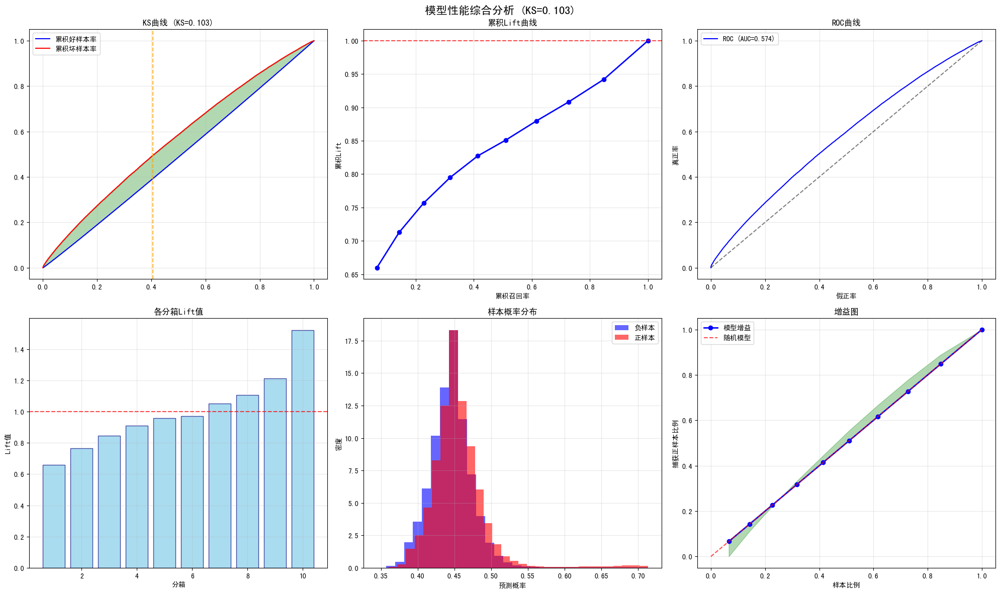

绘制valid的KS和Lift曲线...


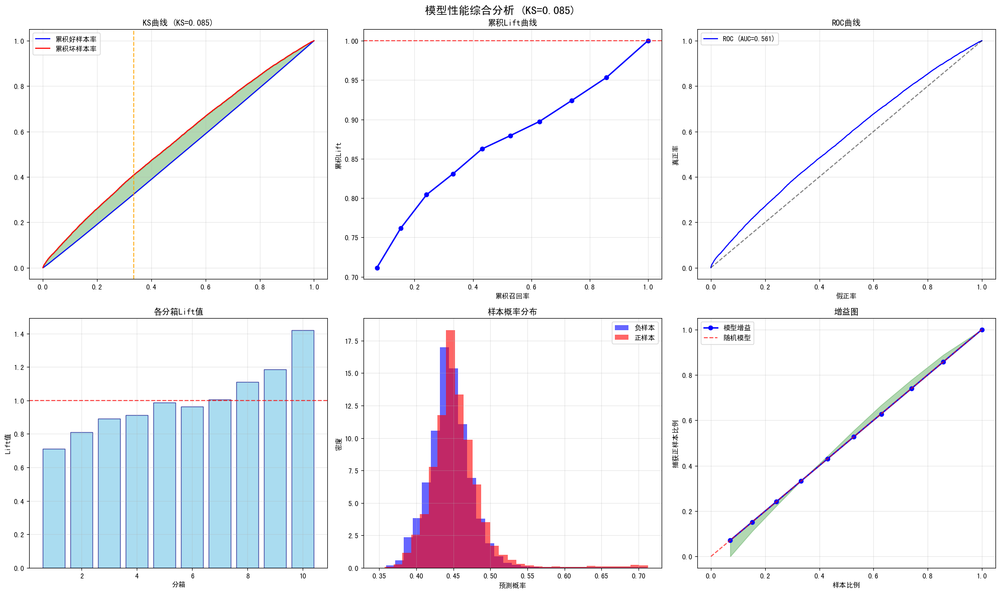

绘制oot的KS和Lift曲线...


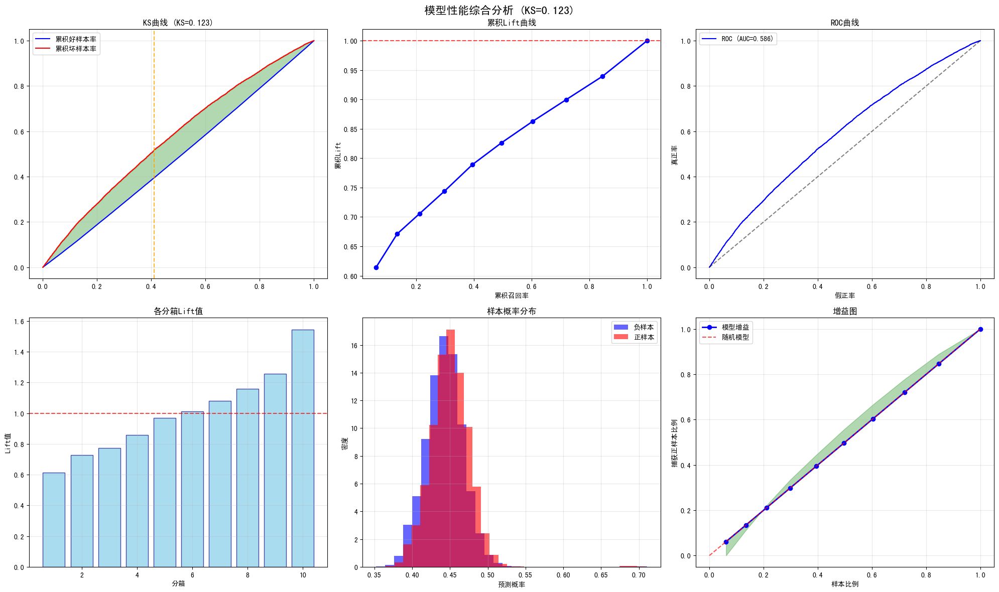

In [94]:
improved_params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    
    # 基础参数
    'n_estimators': 200,  
    'learning_rate': 0.01,
    
    # 树结构参数 
    'max_depth': 4,
    'num_leaves': 10,  
    'min_data_in_leaf': 100,  
    
    # 正则化参数
    'reg_alpha': 2.0,  
    'reg_lambda': 4.0,
    'min_gain_to_split': 0.5,
    
    # 采样参数
    'subsample': 0.8,  
    'subsample_freq': 1,
    'colsample_bytree': 1.0,
    
    'is_unbalance': True,  
    
    # 其他参数
    'random_state': 42,
    'n_jobs': -1,
    'verbosity': 40
}

model = lgb.LGBMClassifier(**improved_params)
train ,valid = train_test_split(train_val_data, test_size=0.2, random_state=42, stratify=train_val_data[label])
model.fit(train[selected_features], train[label])
train['pred_prob'] = model.predict_proba(train[selected_features])[:, 1]
valid['pred_prob'] = model.predict_proba(valid[selected_features])[:, 1]
oot_data['pred_prob'] = model.predict_proba(oot_data[selected_features])[:, 1]

metric_report_plot({'train':train[label], 'valid':valid[label], 'oot':oot_data[label]},{'train':train['pred_prob'], 'valid':valid['pred_prob'], 'oot':oot_data['pred_prob']})

In [97]:
# 计算特征重要性，包括split和gain
importances_gain = model.booster_.feature_importance(importance_type='gain')
importances_split = model.booster_.feature_importance(importance_type='split')
feature_importance_df = pd.DataFrame({
    'feature': selected_features,
    'importance_gain': importances_gain,
    'importance_split': importances_split
}).set_index('feature').sort_values('importance_gain', ascending=False)
display(feature_importance_df)

,importance_gain,importance_split
feature,,
手机号近7天内查询机构数-非银类机构,31846.529236,21
证件号近2个月/3个月内查询笔数变化率-非银类机构,23158.142029,39
手机号近24个月内查询笔数/机构数-消费金融类机构,16063.995041,50
证件号近12个月内查询机构数-消费金融类机构,15039.847107,51
证件号近12个月内查询笔数/机构数-小贷类机构,14500.119080,43
...,...,...
证件号与手机号近6个月内查询机构数差值-网络小贷类机构,0.000000,0
证件号与手机号近12个月内查询笔数比率-消费金融类机构,0.000000,0
手机号近2个月/3个月内查询机构数变化率-网络小贷类机构,0.000000,0


In [102]:
# 查看importance_gain或者importance_split为0的
feature_importance_df[(feature_importance_df['importance_gain']==0) | (feature_importance_df['importance_split']==0)]

,importance_gain,importance_split
feature,,
证件号近6个月内查询笔数-小贷类机构,0.0,0
证件号近24个月内查询机构数-小贷类机构,0.0,0
手机号近12个月内查询机构数-信托类机构,0.0,0
手机号近1个月内查询笔数/机构数-网络零售银行,0.0,0
证件号与手机号近2个月内查询笔数差值-小贷类机构,0.0,0
...,...,...
证件号与手机号近6个月内查询机构数差值-网络小贷类机构,0.0,0
证件号与手机号近12个月内查询笔数比率-消费金融类机构,0.0,0
手机号近2个月/3个月内查询机构数变化率-网络小贷类机构,0.0,0


In [103]:
selected_features_1 = feature_importance_df[feature_importance_df['importance_gain']>0].index.tolist()
selected_features_2 = feature_importance_df[feature_importance_df['importance_split']>0].index.tolist()
selected_features = list(set(selected_features_1) & set(selected_features_2))
len(selected_features)

369

[LightGBM] [Warning] min_gain_to_split is set=0.5, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.5
[LightGBM] [Warning] min_data_in_leaf is set=100, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=100
[LightGBM] [Warning] min_gain_to_split is set=0.5, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.5
[LightGBM] [Warning] min_data_in_leaf is set=100, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=100
[LightGBM] [Info] Number of positive: 78936, number of negative: 525133
[LightGBM] [Debug] Dataset::GetMultiBinFromSparseFeatures: sparse rate 0.778387
[LightGBM] [Debug] Dataset::GetMultiBinFromAllFeatures: sparse rate 0.168288
[LightGBM] [Debug] init for col-wise cost 0.022885 seconds, init for row-wise cost 0.132746 seconds
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.074982 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory

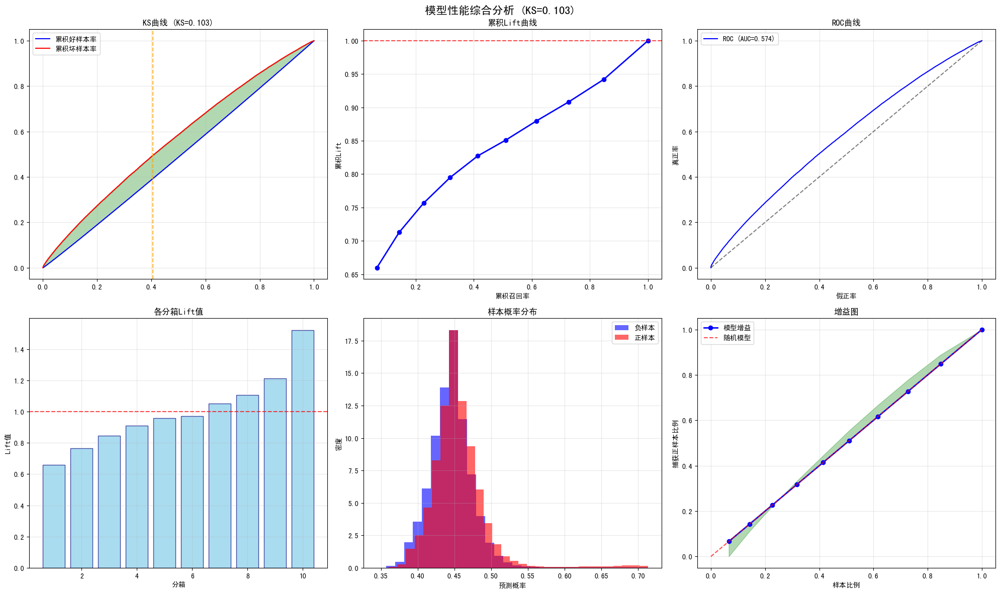

绘制valid的KS和Lift曲线...


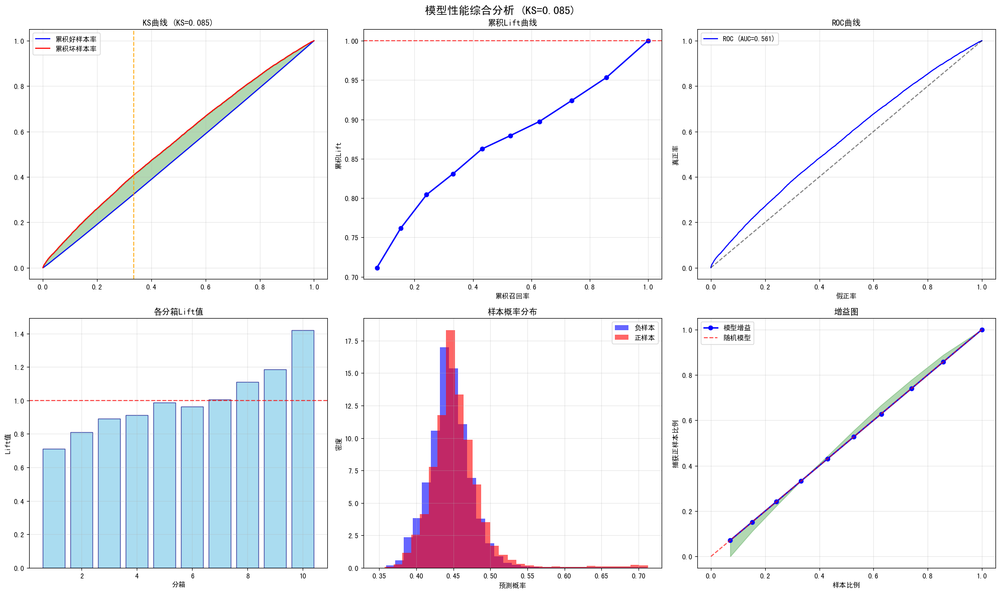

绘制oot的KS和Lift曲线...


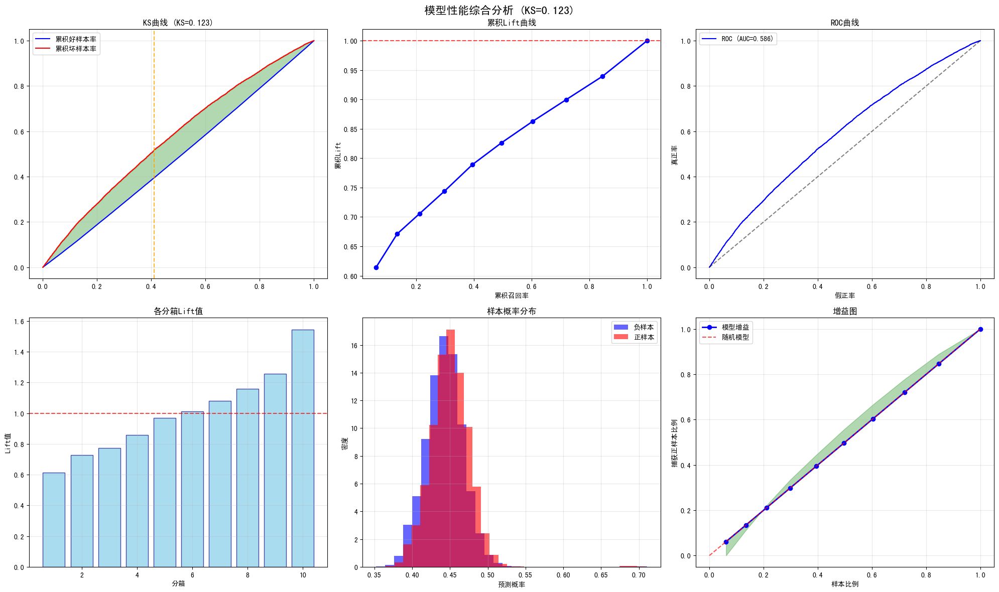

In [104]:
improved_params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    
    # 基础参数
    'n_estimators': 200,  
    'learning_rate': 0.01,
    
    # 树结构参数 
    'max_depth': 4,
    'num_leaves': 10,  
    'min_data_in_leaf': 100,  
    
    # 正则化参数
    'reg_alpha': 2.0,  
    'reg_lambda': 4.0,
    'min_gain_to_split': 0.5,
    
    # 采样参数
    'subsample': 0.8,  
    'subsample_freq': 1,
    'colsample_bytree': 1.0,
    
    'is_unbalance': True,  
    
    # 其他参数
    'random_state': 42,
    'n_jobs': -1,
    'verbosity': 40
}

model = lgb.LGBMClassifier(**improved_params)
train ,valid = train_test_split(train_val_data, test_size=0.2, random_state=42, stratify=train_val_data[label])
model.fit(train[selected_features], train[label])
train['pred_prob'] = model.predict_proba(train[selected_features])[:, 1]
valid['pred_prob'] = model.predict_proba(valid[selected_features])[:, 1]
oot_data['pred_prob'] = model.predict_proba(oot_data[selected_features])[:, 1]

metric_report_plot({'train':train[label], 'valid':valid[label], 'oot':oot_data[label]},{'train':train['pred_prob'], 'valid':valid['pred_prob'], 'oot':oot_data['pred_prob']})

In [ ]:
importances_gain = model.booster_.feature_importance(importance_type='gain')
importances_split = model.booster_.feature_importance(importance_type='split')
feature_importance_df = pd.DataFrame({
    'feature': selected_features,
    'importance_gain': importances_gain,
    'importance_split': importances_split
}).set_index('feature').sort_values('importance_gain', ascending=False)
display(feature_importance_df)

,importance_gain,importance_split
feature,,
手机号近7天内查询机构数-非银类机构,31846.529236,21
证件号近2个月/3个月内查询笔数变化率-非银类机构,23158.142029,39
手机号近24个月内查询笔数/机构数-消费金融类机构,16063.995041,50
证件号近12个月内查询机构数-消费金融类机构,15039.847107,51
证件号近12个月内查询笔数/机构数-小贷类机构,14500.119080,43
...,...,...
手机号近24个月内查询笔数-其他机构,96.113297,1
证件号_手机号_近6个月内查询机构数一致率-网络零售银行,94.200302,1
证件号近3个月内查询笔数/机构数-非银类机构,90.769203,1


In [106]:
selected_features_1 = feature_importance_df[feature_importance_df['importance_gain']>0].index.tolist()
selected_features_2 = feature_importance_df[feature_importance_df['importance_split']>0].index.tolist()
selected_features = list(set(selected_features_1) & set(selected_features_2))
len(selected_features)

367

[LightGBM] [Warning] min_gain_to_split is set=0.5, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.5
[LightGBM] [Warning] min_data_in_leaf is set=100, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=100
[LightGBM] [Warning] min_gain_to_split is set=0.5, min_split_gain=0.0 will be ignored. Current value: min_gain_to_split=0.5
[LightGBM] [Warning] min_data_in_leaf is set=100, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=100
[LightGBM] [Info] Number of positive: 78936, number of negative: 525133
[LightGBM] [Debug] Dataset::GetMultiBinFromSparseFeatures: sparse rate 0.778387
[LightGBM] [Debug] Dataset::GetMultiBinFromAllFeatures: sparse rate 0.168473
[LightGBM] [Debug] init for col-wise cost 0.021817 seconds, init for row-wise cost 0.144781 seconds
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.075656 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory

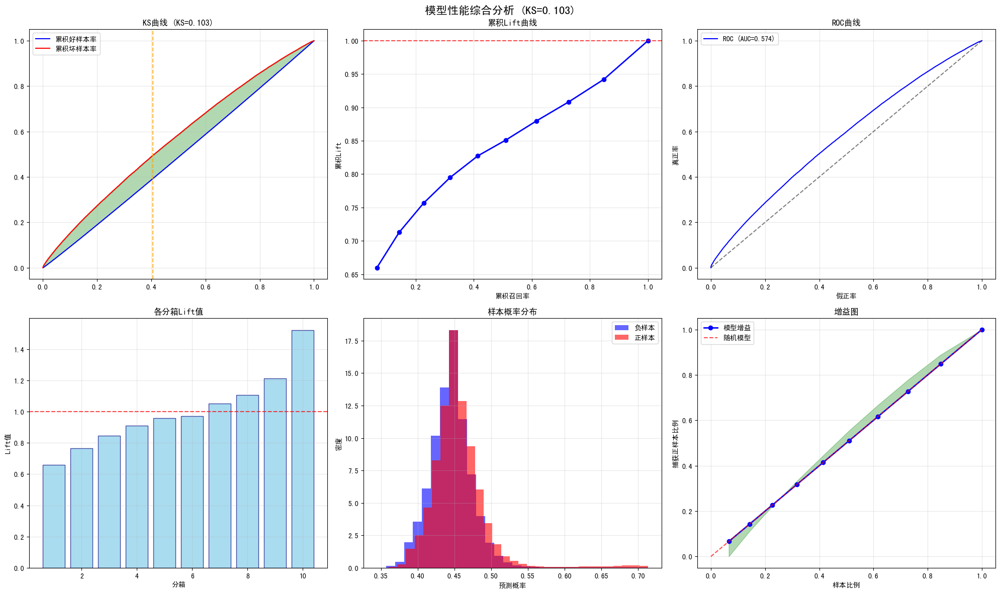

绘制valid的KS和Lift曲线...


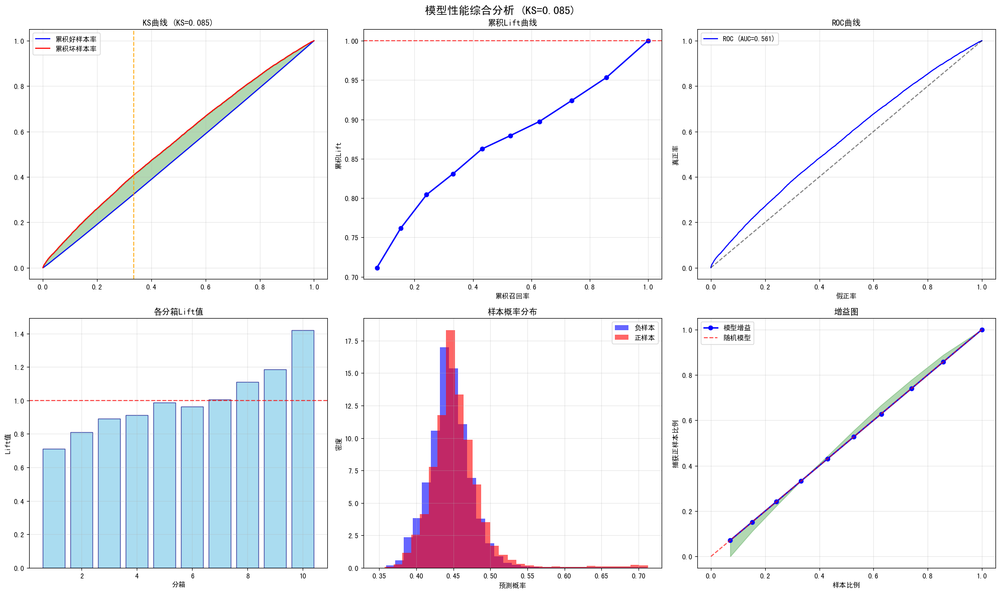

绘制oot的KS和Lift曲线...


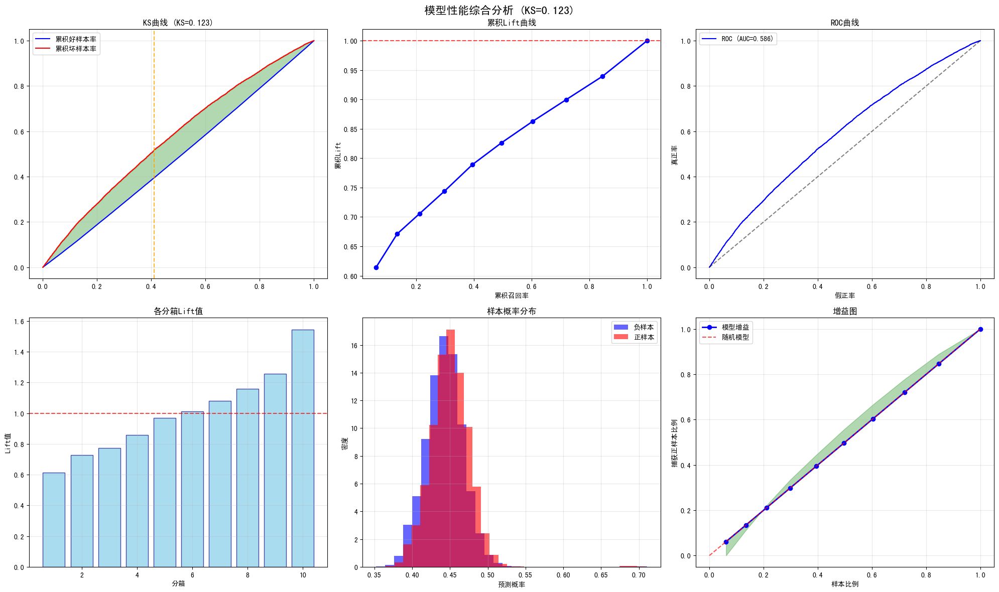

In [107]:
improved_params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    
    # 基础参数
    'n_estimators': 200,  
    'learning_rate': 0.01,
    
    # 树结构参数 
    'max_depth': 4,
    'num_leaves': 10,  
    'min_data_in_leaf': 100,  
    
    # 正则化参数
    'reg_alpha': 2.0,  
    'reg_lambda': 4.0,
    'min_gain_to_split': 0.5,
    
    # 采样参数
    'subsample': 0.8,  
    'subsample_freq': 1,
    'colsample_bytree': 1.0,
    
    'is_unbalance': True,  
    
    # 其他参数
    'random_state': 42,
    'n_jobs': -1,
    'verbosity': 40
}

model = lgb.LGBMClassifier(**improved_params)
train ,valid = train_test_split(train_val_data, test_size=0.2, random_state=42, stratify=train_val_data[label])
model.fit(train[selected_features], train[label])
train['pred_prob'] = model.predict_proba(train[selected_features])[:, 1]
valid['pred_prob'] = model.predict_proba(valid[selected_features])[:, 1]
oot_data['pred_prob'] = model.predict_proba(oot_data[selected_features])[:, 1]

metric_report_plot({'train':train[label], 'valid':valid[label], 'oot':oot_data[label]},{'train':train['pred_prob'], 'valid':valid['pred_prob'], 'oot':oot_data['pred_prob']})

In [108]:
# 计算特征重要性，包括split和gain
importances_gain = model.booster_.feature_importance(importance_type='gain')
importances_split = model.booster_.feature_importance(importance_type='split')
feature_importance_df = pd.DataFrame({
    'feature': selected_features,
    'importance_gain': importances_gain,
    'importance_split': importances_split
}).set_index('feature').sort_values('importance_gain', ascending=False)
display(feature_importance_df)

,importance_gain,importance_split
feature,,
手机号近7天内查询机构数-非银类机构,31846.529236,21
证件号近2个月/3个月内查询笔数变化率-非银类机构,23158.142029,39
手机号近24个月内查询笔数/机构数-消费金融类机构,16063.995041,50
证件号近12个月内查询机构数-消费金融类机构,15039.847107,51
证件号近12个月内查询笔数/机构数-小贷类机构,14500.119080,43
...,...,...
手机号近2个月内查询机构数占比-融资租赁类机构,103.016998,1
证件号近24个月内查询笔数/机构数-网络小贷类机构,100.329002,1
手机号近24个月内查询笔数-其他机构,96.113297,1


In [129]:
feature_importance_df.head(20)

,importance_gain,importance_split
feature,,
手机号近7天内查询机构数-非银类机构,31846.529236,21
证件号近2个月/3个月内查询笔数变化率-非银类机构,23158.142029,39
手机号近24个月内查询笔数/机构数-消费金融类机构,16063.995041,50
证件号近12个月内查询机构数-消费金融类机构,15039.847107,51
证件号近12个月内查询笔数/机构数-小贷类机构,14500.119080,43
证件号近1个月/2个月内查询笔数变化率-非银类机构,14220.879036,34
证件号近24个月内查询笔数/机构数-传统银行,13891.175919,42
证件号近6个月内查询笔数/机构数,11843.624908,36
证件号近6个月/12个月内查询笔数变化率-融资租赁类机构,11221.125053,30


In [109]:
feature_importance_df.index.tolist()

['手机号近7天内查询机构数-非银类机构',
 '证件号近2个月/3个月内查询笔数变化率-非银类机构',
 '手机号近24个月内查询笔数/机构数-消费金融类机构',
 '证件号近12个月内查询机构数-消费金融类机构',
 '证件号近12个月内查询笔数/机构数-小贷类机构',
 '证件号近1个月/2个月内查询笔数变化率-非银类机构',
 '证件号近24个月内查询笔数/机构数-传统银行',
 '证件号近6个月内查询笔数/机构数',
 '证件号近6个月/12个月内查询笔数变化率-融资租赁类机构',
 '证件号近24个月内查询机构数占比-融资租赁类机构',
 '手机号近3天内查询机构数',
 '证件号近3个月/6个月内查询笔数变化率-非银类机构',
 '证件号近1个月内查询机构数-非银类机构',
 '证件号_手机号_近24个月内查询笔数一致率-网络零售银行',
 '证件号近24个月内查询机构数占比-网络小贷类机构',
 '证件号与手机号近3个月内查询机构数差值-助贷类机构',
 '手机号近3个月/6个月内查询机构数变化率-非银类机构',
 '证件号_手机号_近6个月内查询笔数一致率-小贷类机构',
 '证件号近1个月/2个月内查询笔数变化率-网络小贷类机构',
 '证件号近6个月/12个月内查询笔数变化率-网络小贷类机构',
 '证件号_手机号_近12个月内查询笔数一致率-融资租赁类机构',
 '手机号近3个月/6个月内查询笔数变化率-融资租赁类机构',
 '证件号近24个月内查询笔数/机构数-银行类机构',
 '手机号近3个月/6个月内查询机构数变化率-消费金融类机构',
 '证件号_手机号_近6个月内查询笔数一致率',
 '手机号近1个月内查询机构数-融资租赁类机构',
 '手机号近1个月内查询笔数占比-网络小贷类机构',
 '手机号近2个月内查询机构数-非银类机构',
 '证件号_手机号_近12个月内查询笔数一致率-消费金融类机构',
 '证件号与手机号近12个月内查询笔数差值-银行类机构',
 '证件号近3个月/6个月内查询笔数变化率-网络小贷类机构',
 '证件号与手机号近1个月内查询机构数差值-非银类机构',
 '证件号近6个月内查询机构数',
 '手机号近2个月内查询机构数-融资租赁类机构',
 '证件号近3个月/6个月内查询机构数变化率-非银类机构',
 '

In [110]:
joblib.dump(model, 'high_model_衍生1_367.pkl')

['high_model_衍生1_367.pkl']

In [111]:
feature_importance_df.to_csv('feature_importance_衍生1_367.csv')

In [ ]:
feature_importance_df

In [ ]:
selected_features = feature_importance_df.index.tolist()

[LightGBM] [Warning] min_data_in_leaf is set=2000, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=2000
[LightGBM] [Warning] min_data_in_leaf is set=2000, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=2000
[LightGBM] [Info] Number of positive: 63820, number of negative: 498408
[LightGBM] [Debug] Dataset::GetMultiBinFromSparseFeatures: sparse rate 0.799488
[LightGBM] [Debug] Dataset::GetMultiBinFromAllFeatures: sparse rate 0.158805
[LightGBM] [Debug] init for col-wise cost 0.018635 seconds, init for row-wise cost 0.133927 seconds
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.175666 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 52440
[LightGBM] [Info] Number of data points in the train set: 562228, number of used features: 366
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.113513 -> initscore=-2.055352
[LightGBM] [Info] Start training from score -2.

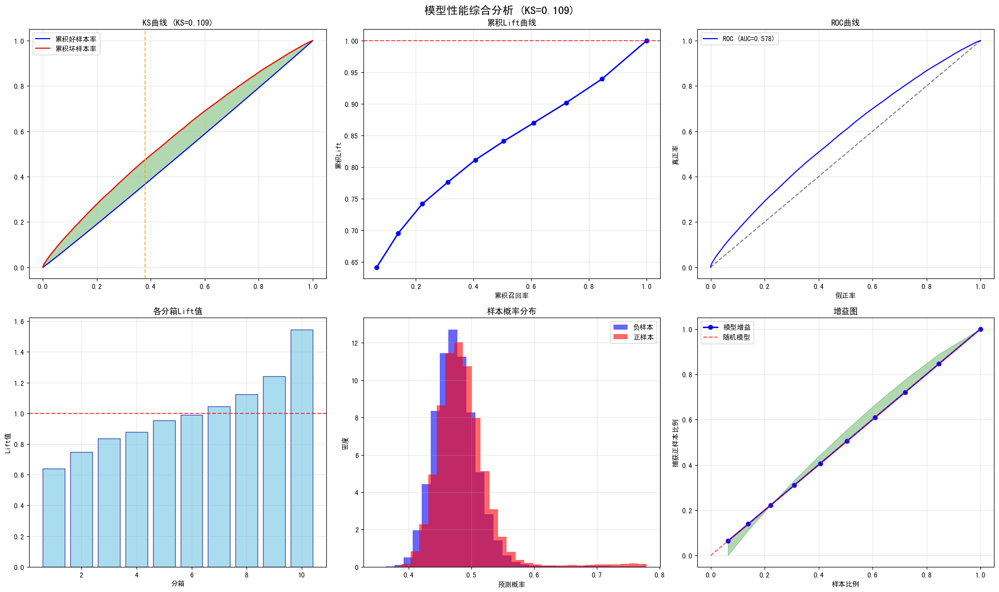

绘制valid的KS和Lift曲线...


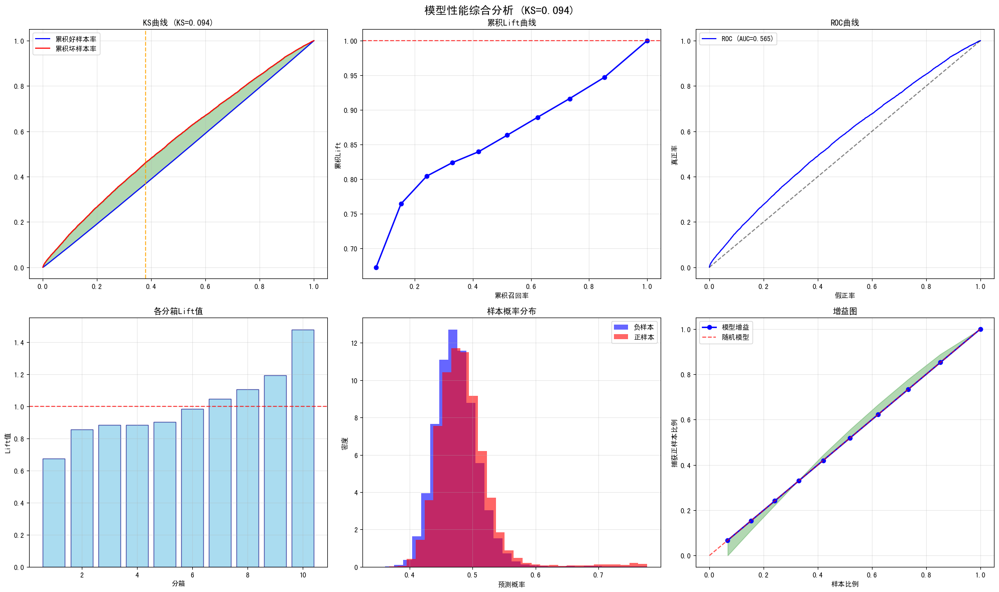

绘制oot的KS和Lift曲线...


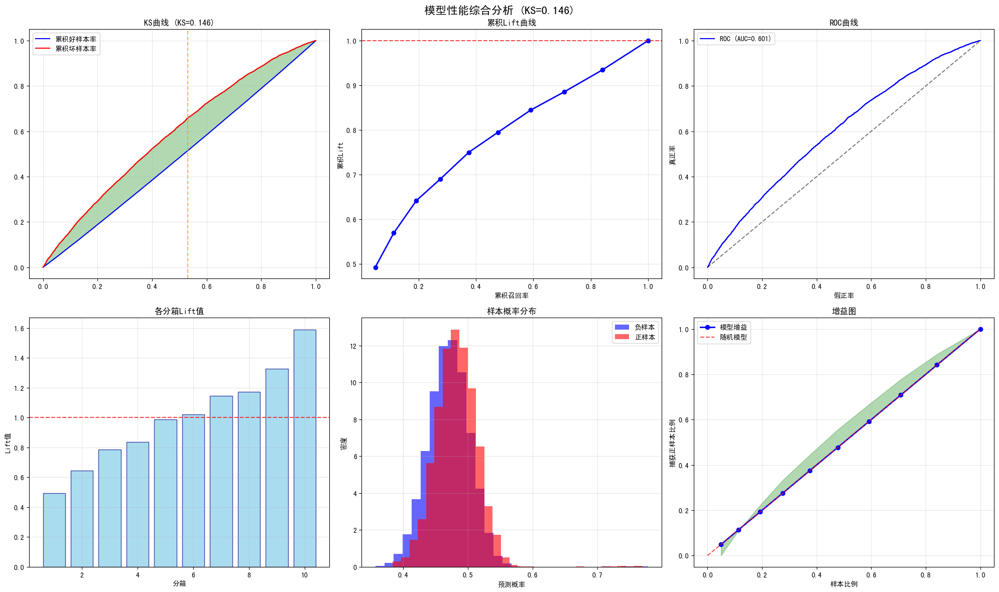

In [148]:
improved_params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    
    # 基础参数
    'n_estimators': 200,  
    'learning_rate': 0.015,
    
    # 树结构参数 
    'max_depth': 4,
    'num_leaves': 8,  
    'min_data_in_leaf': 2000,  
    
    # 正则化参数
    'reg_alpha': 3.0,  
    'reg_lambda': 5.0,
    'min_split_gain': 0.6,   
    
    # 采样参数
    'subsample': 0.8, 
    'subsample_freq': 1, 
    'colsample_bytree': 0.8,
    
    'is_unbalance': True,  
    
    # 其他参数
    'random_state': 42,
    'n_jobs': -1,
    'verbosity': 40
}

model = lgb.LGBMClassifier(**improved_params)
train ,valid = train_test_split(train_val_data, test_size=0.2, random_state=42, stratify=train_val_data[label])
model.fit(train[selected_features], train[label])
train['pred_prob'] = model.predict_proba(train[selected_features])[:, 1]
valid['pred_prob'] = model.predict_proba(valid[selected_features])[:, 1]
oot_data['pred_prob'] = model.predict_proba(oot_data[selected_features])[:, 1]

metric_report_plot({'train':train[label], 'valid':valid[label], 'oot':oot_data[label]},{'train':train['pred_prob'], 'valid':valid['pred_prob'], 'oot':oot_data['pred_prob']})

In [149]:
sampled_data.shape

(751891, 2003)

In [150]:
sampled_data['pred_prob'] = model.predict_proba(sampled_data[selected_features])[:, 1]

[LightGBM] [Warning] min_data_in_leaf is set=2000, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=2000


In [151]:
train_val_label_dict = {}
for i in sampled_data['合作方'].unique():
    train_val_label_dict[i] = sampled_data[sampled_data['合作方']==i]['flag']
train_pred_prob_dict = {}
for i in sampled_data['合作方'].unique():
    train_pred_prob_dict[i] = sampled_data[sampled_data['合作方']==i]['pred_prob']


df_res_all = pd.DataFrame()
for key in train_val_label_dict.keys():
    # print(f"样本量: {len(train_val_label_dict[key])}")
    # metric_report_plot({str(encoding_dict_inv[key]):train_val_label_dict[key]},{str(encoding_dict_inv[key]):train_pred_prob_dict[key]},n_bins=30)
    df_res = generate_metric_table({str(key):train_val_label_dict[key]},{str(key):train_pred_prob_dict[key]})
    df_res_all = pd.concat([df_res_all, df_res])


for partner in df_after_filter['合作方'].unique():
    # 获取该合作方的数据
    partner_data = df_after_filter[df_after_filter['合作方'] == partner]
    

    coverage_rate = partner_data[keep_features].notnull().any(axis=1).mean() # notnull()表示非空，any(axis=1)表示行方向上至少有一个非空

    print(f"{partner}的查的率: {coverage_rate:.4f}")
    
    # 更新df_res_all中的覆盖率
    df_res_all.loc[df_res_all['数据类别'] == partner, '入模查的率'] = coverage_rate
df_res_all

shanxiqn的查的率: 0.9972
nwd的查的率: 0.9735
zijie的查的率: 0.9898
hc_new的查的率: 1.0000
hc_old的查的率: 1.0000
weixin_old的查的率: 1.0000
weixin_oldjc的查的率: 1.0000
weixin_new的查的率: 1.0000
weixin_newjc的查的率: 0.9998
hc_A的查的率: 0.9967
hc_B的查的率: 1.0000
hc_C的查的率: 1.0000
yqg的查的率: 0.9994
zhongan_oldcg的查的率: 1.0000
zhongan_oldzr的查的率: 1.0000
zhongan_newcg的查的率: 1.0000
zhongan_newzr的查的率: 1.0000
lexin_type2的查的率: 0.9996
lexin_type4的查的率: 0.9988
lexin_type5的查的率: 0.9728
lexin_type1的查的率: 0.9949
lexin_type3的查的率: 0.9907


,数据类别,样本总计,0-样本计数,1-样本计数,0-样本占比,1-样本占比,AUC值,KS值,入模查的率
0,hc_new,52838,46838,6000,88.64%,11.36%,0.5481,0.0731,0.999983
0,hc_old,47580,42177,5403,88.64%,11.36%,0.6012,0.1457,1.000000
0,weixin_old,110620,98059,12561,88.64%,11.36%,0.5690,0.0998,1.000000
0,weixin_oldjc,37324,33086,4238,88.65%,11.35%,0.5657,0.0965,1.000000
0,weixin_new,39002,34574,4428,88.65%,11.35%,0.5282,0.0485,0.999964
0,weixin_newjc,10840,9609,1231,88.64%,11.36%,0.5553,0.0885,0.999798
0,hc_A,23944,21225,2719,88.64%,11.36%,0.5436,0.0684,0.996677
0,hc_B,12778,11327,1451,88.64%,11.36%,0.5687,0.1099,1.000000
0,hc_C,37664,33387,4277,88.64%,11.36%,0.5549,0.0793,1.000000
0,yqg,31068,27540,3528,88.64%,11.36%,0.5464,0.0763,0.999401


In [164]:
importances_gain = model.booster_.feature_importance(importance_type='gain')
importances_split = model.booster_.feature_importance(importance_type='split')
feature_importance_df = pd.DataFrame({
    'feature': selected_features,
    'importance_gain': importances_gain,
    'importance_split': importances_split
}).set_index('feature').sort_values('importance_gain', ascending=False)
display(feature_importance_df)

,importance_gain,importance_split
feature,,
证件号近2个月/3个月内查询笔数变化率-非银类机构,15093.394958,31
证件号近12个月内查询机构数-消费金融类机构,14615.148102,53
证件号近12个月内查询笔数/机构数-小贷类机构,11946.959953,37
手机号近7天内查询机构数-非银类机构,11534.330902,9
手机号近24个月内查询笔数/机构数-消费金融类机构,11048.974960,38
...,...,...
手机号近2个月/3个月内查询笔数变化率-消费金融类机构,0.000000,0
手机号近3个月内查询机构数占比-小贷类机构,0.000000,0
手机号近3个月内查询笔数占比-网络小贷类机构,0.000000,0


In [165]:
feature_importance_df[feature_importance_df['importance_gain']>0].sort_values(by='importance_gain',ascending=False)

,importance_gain,importance_split
feature,,
证件号近2个月/3个月内查询笔数变化率-非银类机构,15093.394958,31
证件号近12个月内查询机构数-消费金融类机构,14615.148102,53
证件号近12个月内查询笔数/机构数-小贷类机构,11946.959953,37
手机号近7天内查询机构数-非银类机构,11534.330902,9
手机号近24个月内查询笔数/机构数-消费金融类机构,11048.974960,38
...,...,...
证件号近24个月内查询笔数-消费金融类机构,116.443001,1
证件号近2个月内查询笔数/机构数,114.413002,1
证件号近12个月内查询笔数/机构数-消费金融类机构,112.698997,1


In [166]:
feature_importance_df.to_csv('feature_importance_衍生2_243.csv',index=False)

In [152]:
joblib.dump(model, 'model_high_2.pkl')

['model_high_2.pkl']

In [157]:
raw_high.shape

(1659298, 2003)

In [159]:
raw_high['pred_prob'] = model.predict_proba(raw_high[selected_features])[:,1]

[LightGBM] [Warning] min_data_in_leaf is set=2000, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=2000


/var/folders/v1/ch71pmtn60dbr0m_t7s_ch1m0000gn/T/ipykernel_2921/472459811.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  raw_high['pred_prob'] = model.predict_proba(raw_high[selected_features])[:,1]


In [161]:
raw_high['pred_prob'].describe()

count    1.659298e+06
mean     4.747475e-01
std      3.648888e-02
min      3.470762e-01
25%      4.509145e-01
50%      4.711110e-01
75%      4.943161e-01
max      7.793662e-01
Name: pred_prob, dtype: float64

<Axes: >

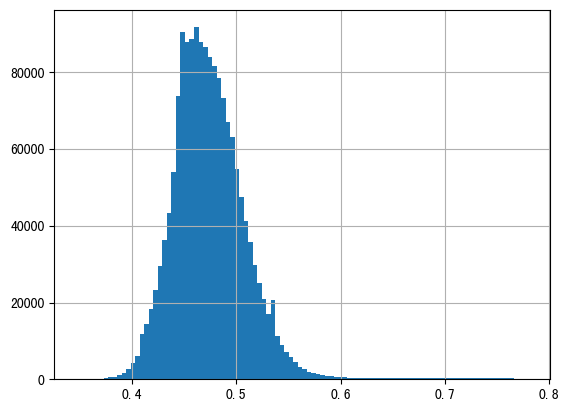

In [162]:
raw_high['pred_prob'].hist(bins=100)

In [163]:
raw_high[not_features+[label]+['pred_prob']].to_csv('raw_df_high_2_pred.csv',index=False)

# 采样后效果

In [29]:
# feature_importance_df.to_csv('feature_importance_衍生1_367.csv')
feature_importance_df = pd.read_csv('feature_importance_衍生1_367.csv')

In [30]:
feature_importance_df

,feature,importance_gain,importance_split
0,手机号近7天内查询机构数-非银类机构,31846.529236,21
1,证件号近2个月/3个月内查询笔数变化率-非银类机构,23158.142029,39
2,手机号近24个月内查询笔数/机构数-消费金融类机构,16063.995041,50
3,证件号近12个月内查询机构数-消费金融类机构,15039.847107,51
4,证件号近12个月内查询笔数/机构数-小贷类机构,14500.119080,43
...,...,...,...
362,手机号近2个月内查询机构数占比-融资租赁类机构,103.016998,1
363,证件号近24个月内查询笔数/机构数-网络小贷类机构,100.329002,1
364,手机号近24个月内查询笔数-其他机构,96.113297,1
365,证件号_手机号_近6个月内查询机构数一致率-网络零售银行,94.200302,1


In [34]:
selected_features = feature_importance_df['feature'].tolist()
selected_features

['手机号近7天内查询机构数-非银类机构',
 '证件号近2个月/3个月内查询笔数变化率-非银类机构',
 '手机号近24个月内查询笔数/机构数-消费金融类机构',
 '证件号近12个月内查询机构数-消费金融类机构',
 '证件号近12个月内查询笔数/机构数-小贷类机构',
 '证件号近1个月/2个月内查询笔数变化率-非银类机构',
 '证件号近24个月内查询笔数/机构数-传统银行',
 '证件号近6个月内查询笔数/机构数',
 '证件号近6个月/12个月内查询笔数变化率-融资租赁类机构',
 '证件号近24个月内查询机构数占比-融资租赁类机构',
 '手机号近3天内查询机构数',
 '证件号近3个月/6个月内查询笔数变化率-非银类机构',
 '证件号近1个月内查询机构数-非银类机构',
 '证件号_手机号_近24个月内查询笔数一致率-网络零售银行',
 '证件号近24个月内查询机构数占比-网络小贷类机构',
 '证件号与手机号近3个月内查询机构数差值-助贷类机构',
 '手机号近3个月/6个月内查询机构数变化率-非银类机构',
 '证件号_手机号_近6个月内查询笔数一致率-小贷类机构',
 '证件号近1个月/2个月内查询笔数变化率-网络小贷类机构',
 '证件号近6个月/12个月内查询笔数变化率-网络小贷类机构',
 '证件号_手机号_近12个月内查询笔数一致率-融资租赁类机构',
 '手机号近3个月/6个月内查询笔数变化率-融资租赁类机构',
 '证件号近24个月内查询笔数/机构数-银行类机构',
 '手机号近3个月/6个月内查询机构数变化率-消费金融类机构',
 '证件号_手机号_近6个月内查询笔数一致率',
 '手机号近1个月内查询机构数-融资租赁类机构',
 '手机号近1个月内查询笔数占比-网络小贷类机构',
 '手机号近2个月内查询机构数-非银类机构',
 '证件号_手机号_近12个月内查询笔数一致率-消费金融类机构',
 '证件号与手机号近12个月内查询笔数差值-银行类机构',
 '证件号近3个月/6个月内查询笔数变化率-网络小贷类机构',
 '证件号与手机号近1个月内查询机构数差值-非银类机构',
 '证件号近6个月内查询机构数',
 '手机号近2个月内查询机构数-融资租赁类机构',
 '证件号近3个月/6个月内查询机构数变化率-非银类机构',
 '

[LightGBM] [Warning] min_data_in_leaf is set=2000, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=2000
[LightGBM] [Warning] min_data_in_leaf is set=2000, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=2000
[LightGBM] [Info] Number of positive: 125050, number of negative: 941592
[LightGBM] [Debug] Dataset::GetMultiBinFromSparseFeatures: sparse rate 0.806685
[LightGBM] [Debug] Dataset::GetMultiBinFromAllFeatures: sparse rate 0.161663
[LightGBM] [Debug] init for col-wise cost 0.041404 seconds, init for row-wise cost 0.303114 seconds
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.389648 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 52369
[LightGBM] [Info] Number of data points in the train set: 1066642, number of used features: 367
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.049999 -> initscore=-2.944450
[LightGBM] [Info] Start training from score -

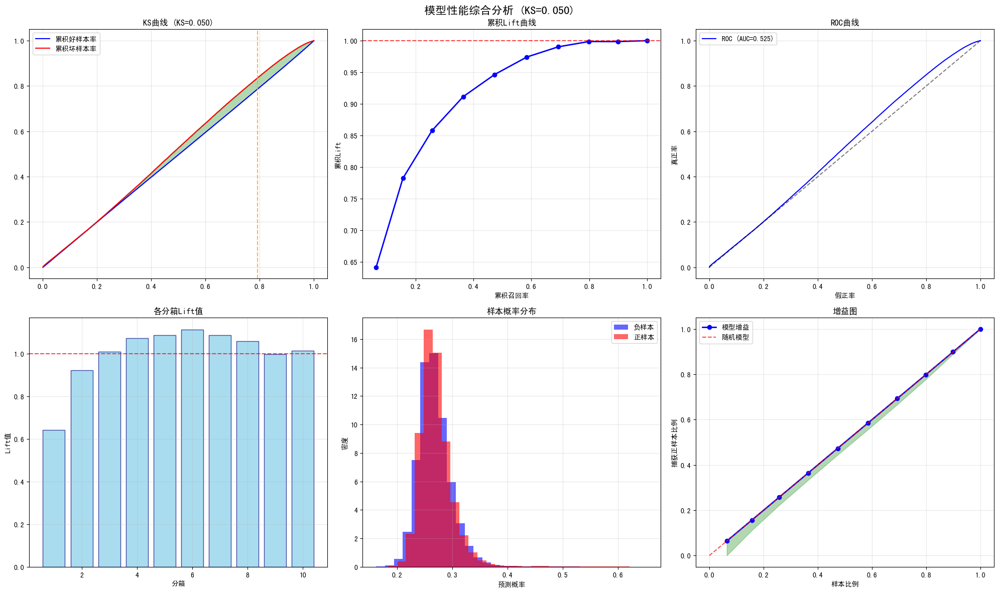

绘制valid的KS和Lift曲线...


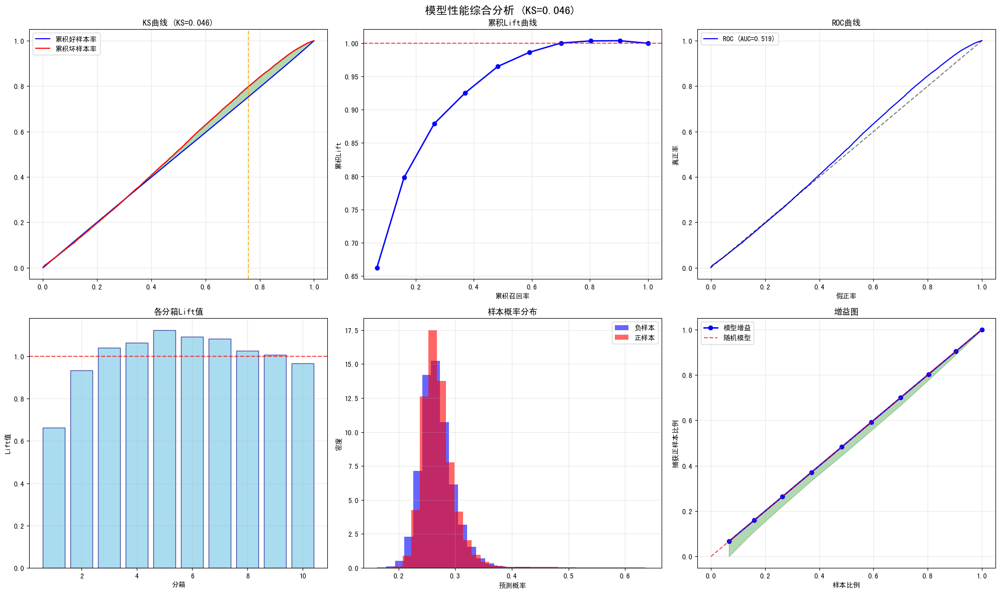

绘制oot的KS和Lift曲线...


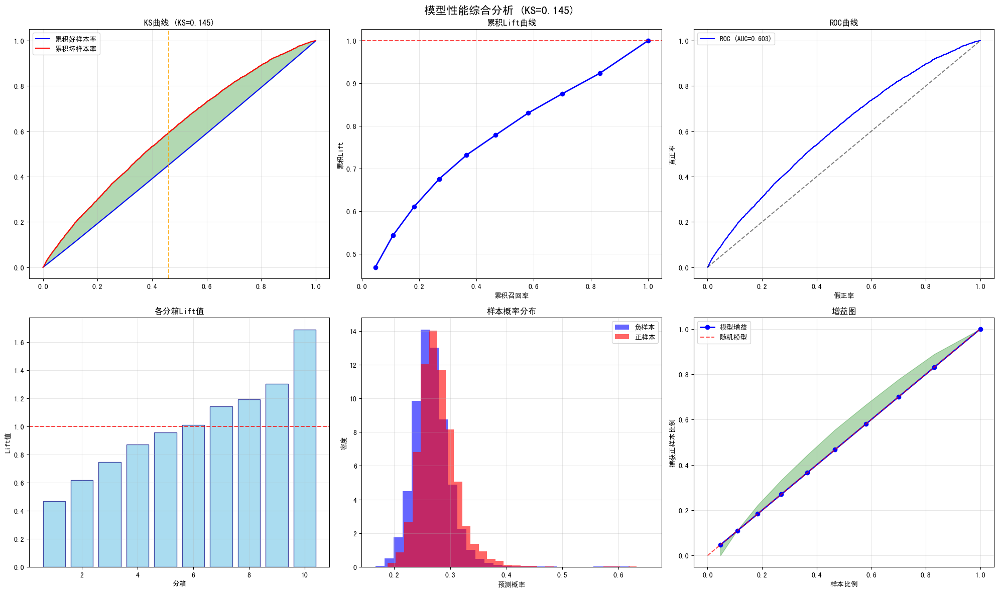

In [36]:
improved_params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    
    # 基础参数
    'n_estimators': 200,  
    'learning_rate': 0.015,
    
    # 树结构参数 
    'max_depth': 4,
    'num_leaves': 8,  
    'min_data_in_leaf': 2000,  
    
    # 正则化参数
    'reg_alpha': 3.0,  
    'reg_lambda': 5.0,
    'min_split_gain': 0.6,   
    
    # 采样参数
    'subsample': 0.8, 
    'subsample_freq': 1, 
    'colsample_bytree': 0.8,
    
    'is_unbalance': True,  
    
    # 其他参数
    'random_state': 42,
    'n_jobs': -1,
    'verbosity': 40
}

model = lgb.LGBMClassifier(**improved_params)
train ,valid = train_test_split(train_val_data, test_size=0.2, random_state=42, stratify=train_val_data[label])
model.fit(train[selected_features], train[label],sample_weight=train['weight'])
train['pred_prob'] = model.predict_proba(train[selected_features])[:, 1]
valid['pred_prob'] = model.predict_proba(valid[selected_features])[:, 1]
oot_data['pred_prob'] = model.predict_proba(oot_data[selected_features])[:, 1]

metric_report_plot({'train':train[label], 'valid':valid[label], 'oot':oot_data[label]},{'train':train['pred_prob'], 'valid':valid['pred_prob'], 'oot':oot_data['pred_prob']})

In [ ]:
sampled_data.shape

(751891, 2003)

In [37]:
raw_high_after_202312['pred_prob'] = model.predict_proba(raw_high_after_202312[selected_features])[:, 1]

[LightGBM] [Warning] min_data_in_leaf is set=2000, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=2000


/var/folders/v1/ch71pmtn60dbr0m_t7s_ch1m0000gn/T/ipykernel_15462/1836071666.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  raw_high_after_202312['pred_prob'] = model.predict_proba(raw_high_after_202312[selected_features])[:, 1]


In [ ]:
train_val_label_dict = {}
for i in raw_high_after_202312['合作方'].unique():
    train_val_label_dict[i] = raw_high_after_202312[raw_high_after_202312['合作方']==i]['flag']
train_pred_prob_dict = {}
for i in raw_high_after_202312['合作方'].unique():
    train_pred_prob_dict[i] = raw_high_after_202312[raw_high_after_202312['合作方']==i]['pred_prob']


df_res_all = pd.DataFrame()
for key in train_val_label_dict.keys():
    # print(f"样本量: {len(train_val_label_dict[key])}")
    # metric_report_plot({str(encoding_dict_inv[key]):train_val_label_dict[key]},{str(encoding_dict_inv[key]):train_pred_prob_dict[key]},n_bins=30)
    df_res = generate_metric_table({str(key):train_val_label_dict[key]},{str(key):train_pred_prob_dict[key]})
    df_res_all = pd.concat([df_res_all, df_res])

df_res_all

NameError: name 'df_after_filter' is not defined

In [39]:
df_res_all

,数据类别,样本总计,0-样本计数,1-样本计数,0-样本占比,1-样本占比,AUC值,KS值
0,hc_new,60000,54000,6000,90.00%,10.00%,0.5421,0.0651
0,hc_old,78305,72902,5403,93.10%,6.90%,0.5971,0.1379
0,weixin_old,168396,98059,70337,58.23%,41.77%,0.5567,0.0798
0,weixin_oldjc,40300,33086,7214,82.10%,17.90%,0.5618,0.0922
0,weixin_new,55824,34574,21250,61.93%,38.07%,0.5216,0.0324
0,weixin_newjc,14820,13589,1231,91.69%,8.31%,0.5657,0.0952
0,hc_A,54766,52047,2719,95.04%,4.96%,0.5643,0.0942
0,hc_B,24910,23459,1451,94.18%,5.82%,0.6003,0.1447
0,hc_C,75641,71364,4277,94.35%,5.65%,0.5651,0.0982
0,yqg,70062,66534,3528,94.96%,5.04%,0.5558,0.0916
